# Proyecto III · Minería de Datos

**ISW-911 · Caso de consultoría para Grupo Innova S.A.**

**Equipo:** 
 Miguel Cruz Vargas
 Brian Rodriguez Perez
 Jeremy Rodriguez Esquivel
 Cristopher Quiros Araya.

## Introducción

Grupo Innova S.A. busca usar el historial de ventas para comprender su desempeño comercial y anticipar cambios que requieren una decisión. En este proyecto se analizarán los registros de ventas musicales de Chinook, preparados en el workshop 4 y disponibles en [data_process.csv](../data/data_process.csv). Cada fila representa una línea de factura e incluye datos como la fecha de compra, el cliente, la canción, el género, el país del cliente, la cantidad y el importe.

El punto de partida son los ocho indicadores mensuales aprobados en el Proyecto 2. Cubren el crecimiento de los ingresos y las unidades vendidas, el ingreso promedio por comprador, los clientes activos, la retención, la cobertura por países y la concentración de ingresos por género y por artista. Las fórmulas y las fuentes del Data Warehouse están en el [README](../README.md#kpis-aprobados). Para calcular la concentración en los cinco artistas principales se requiere incorporar la relación entre canción y artista desde el catálogo de Chinook.

## Objetivo del proyecto

Se desarrolla la propuesta vinculada al KPI-04 de retención. Al cierre de cada mes, se busca estimar qué clientes que compraron ese mes volverán a comprar el siguiente. Cada ejemplo representa un cliente comprador y un mes de corte. La Fase I construye la variable objetivo y sus predictores con el historial disponible. La pregunta de recompra queda pendiente de ratificación por el equipo. Se utiliza el historial del workshop hasta diciembre de 2013, conciliado con sus exportaciones originales.

El trabajo incluirá el análisis exploratorio y la preparación de los datos, el ajuste de al menos dos modelos supervisados y su comparación sobre un conjunto de prueba independiente. A partir del desempeño y de las variables más importantes del modelo elegido, se formularán al menos tres recomendaciones para la junta directiva.


## Fase I. Pregunta de negocio y preparación de los datos

**Responsable de esta fase, Brian.** Jeremy continúa con la partición temporal,
el preprocesamiento y el entrenamiento de los dos modelos. Miguel evalúa y
Cristopher prepara la presentación ejecutiva.

### 1. Pregunta y variable objetivo

Se desarrolla la propuesta del KPI-04 del Proyecto II. Al cierre de un mes,
¿qué clientes que compraron ese mes volverán a comprar el mes calendario siguiente?
La dirección comercial podría usar las probabilidades para priorizar un piloto
de seguimiento de compradores recientes. El modelo se evaluará con fechas futuras
antes de recomendar su uso. Un experimento con grupos comparables permitiría
medir después si el contacto genera compras adicionales.

La unidad de análisis es **cliente comprador y mes de corte**. La etiqueta
`RecompraMesSiguiente` vale 1 cuando ese cliente tiene al menos una compra en el
mes siguiente y 0 cuando se observó ese mes completo y el cliente no compró.
Es una clasificación binaria. El historial disponible termina al cierre del mes
de corte. La actividad posterior se utiliza exclusivamente para la etiqueta.

El KPI-04 de febrero, por ejemplo, divide los compradores de enero que volvieron
en febrero entre todos los compradores de enero. Ese grupo aporta las filas de
enero al modelo. Este alcance comprende a compradores del mes de corte.
La captación de clientes nuevos y la reactivación de clientes inactivos requerirían
definir otras poblaciones.

La definición se contrastó con `powerbi/documentacion/catalogo_kpis.json` del
Proyecto II. El notebook se reconstruye desde el CSV del workshop 4.
[Documentación del tablero y KPIs](https://github.com/Brianrp19/chinook_datawarehouse/blob/main/powerbi/README.md)

### 2. Carga y configuración reproducible

Ejecutar las celdas en orden desde la raíz del repositorio o desde `notebooks/`.
En Colab, colocar el CSV en `data/data_process.csv` dentro del directorio de
trabajo. Se necesitan pandas, NumPy y Matplotlib, disponibles en Colab.

**Cobertura adoptada.** Se utiliza diciembre de 2013 como último mes de
resultado. El CSV procesado concilia con las exportaciones originales
`Invoice.csv` e `InvoiceLine.csv` del Lab 4 en sus 2.240 líneas y en los importes
de las 412 facturas. Diciembre contiene 38 líneas en siete facturas por 38,62 UM,
también presentes en la línea base del Data Warehouse del Proyecto II. Con esta
conciliación se adopta el historial cerrado proporcionado para la práctica.

La última venta registrada es del 22 de diciembre. Una última venta anterior al
fin de mes es compatible con esa cobertura. El último mes de corte es noviembre
de 2013 y su resultado se observa en diciembre. Una cohorte con corte en diciembre
requeriría observar enero de 2014.
[Exportaciones originales del Lab 4](https://github.com/Brianrp19/laboratorio4-mineria-datos/tree/main/datos/origen)


In [294]:
from pathlib import Path
import hashlib
import platform
import pandas as pd
import numpy as np

pd.set_option("display.max_rows", 80)
pd.set_option("display.max_columns", 15)

SEMILLA = 42
ULTIMO_MES_RESULTADO_COMPLETO = pd.Period("2013-12", freq="M")
ANIO_INICIO_PRUEBA_PROPUESTO = 2013
ANIO_FIN_ENTRENAMIENTO_INICIAL = 2009
VENTANA_DIAS = 90

raices_posibles = [Path.cwd(), Path.cwd().parent, Path.cwd() / "Proyecto3-mineria-datos"]
raiz = next((p for p in raices_posibles if (p / "data/data_process.csv").is_file()), None)
if raiz is None:
    raise FileNotFoundError("Colocar data/data_process.csv en la raíz del proyecto y ejecutar desde allí o desde notebooks/.")

ruta_csv = raiz / "data/data_process.csv"
ruta_tablas = raiz / "resultados/tablas"
ruta_figuras = raiz / "resultados/figuras"
ruta_tablas.mkdir(parents=True, exist_ok=True)
ruta_figuras.mkdir(parents=True, exist_ok=True)
huella_entrada = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()
ventas_originales = pd.read_csv(ruta_csv)
print(f"CSV recibido: {ventas_originales.shape[0]} filas y {ventas_originales.shape[1]} columnas")
print(f"Python {platform.python_version()}, pandas {pd.__version__}, NumPy {np.__version__}")
print(f"SHA-256 de entrada: {huella_entrada}")
print(f"Último mes de resultado utilizado: {ULTIMO_MES_RESULTADO_COMPLETO}")
display(ventas_originales.head(3))


CSV recibido: 2240 filas y 66 columnas
Python 3.13.17, pandas 3.1.1, NumPy 2.5.5
SHA-256 de entrada: ca4a465b05c5df5a80905b2592c68c911ffc98bf2a3e6126681390401331843b
Último mes de resultado utilizado: 2013-12


,IdLineaFactura,IdFactura,IdCancion,PrecioUnitario,Cantidad,IdCliente,FechaFactura,...,PaisFacturacion_Poland,PaisFacturacion_Portugal,PaisFacturacion_Spain,PaisFacturacion_Sweden,PaisFacturacion_USA,PaisFacturacion_United Kingdom,CategoriaPrecio
0,1,1,2,0.99,1,2,2009-01-01,...,0,0,0,0,0,0,0.99
1,2,1,4,0.99,1,2,2009-01-01,...,0,0,0,0,0,0,0.99
2,3,2,6,0.99,1,4,2009-01-02,...,0,0,0,0,0,0,0.99


### 3. Estructura, tipos, cardinalidad y calidad

Cada fila del CSV representa una línea de factura. Varias líneas pueden
pertenecer a una factura y un cliente puede comprar en diferentes meses.
Se comprueban las claves y la relación importe = precio × cantidad antes de
agregar. La tabla de calidad incluye todos los campos recibidos y cuenta
también cadenas vacías o formadas por espacios.


In [295]:
perfil_columnas = pd.DataFrame({
    "TipoRecibido": ventas_originales.dtypes.astype(str),
    "ValoresDistintos": ventas_originales.nunique(dropna=True),
    "Nulos": ventas_originales.isna().sum(),
    "VaciosTexto": ventas_originales.apply(lambda s: s.astype("string").str.strip().eq("").sum()),
}).rename_axis("Columna").reset_index()
display(perfil_columnas)

ventas = ventas_originales.copy()
ventas["FechaFactura"] = pd.to_datetime(ventas["FechaFactura"], errors="raise")
columnas_requeridas = ["IdLineaFactura", "IdFactura", "IdCliente", "IdCancion", "IdGenero",
                       "FechaFactura", "PrecioUnitario", "Cantidad", "ImporteLinea", "PaisCliente"]
assert ventas[columnas_requeridas].notna().all().all(), "Revisar faltantes en los campos de construcción."
assert not ventas["PaisCliente"].str.strip().eq("").any()
assert ventas["IdLineaFactura"].is_unique, "Hay claves de línea repetidas."
assert not ventas_originales.duplicated().any(), "Revisar filas idénticas antes de continuar."
assert ventas.groupby("IdFactura")[["IdCliente", "FechaFactura"]].nunique().eq(1).all().all()
assert np.isfinite(ventas[["PrecioUnitario", "Cantidad", "ImporteLinea"]].to_numpy()).all()
assert ventas[["PrecioUnitario", "Cantidad", "ImporteLinea"]].gt(0).all().all()
assert np.allclose(ventas["ImporteLinea"], ventas["PrecioUnitario"] * ventas["Cantidad"])
assert ventas["AnioFactura"].eq(ventas["FechaFactura"].dt.year).all()
assert ventas["MesFactura"].eq(ventas["FechaFactura"].dt.month).all()
assert np.allclose(ventas["DuracionMinutos"], ventas["DuracionMilisegundos"] / 60000)

ventas["MesVenta"] = ventas["FechaFactura"].dt.to_period("M")
meses = pd.period_range(ventas["MesVenta"].min(), ventas["MesVenta"].max(), freq="M")
assert set(ventas["MesVenta"]) == set(meses), "Hay meses sin registros cuya cobertura se debe confirmar."
assert meses.min() < ULTIMO_MES_RESULTADO_COMPLETO <= meses.max()

resumen_entrada = pd.Series({
    "LineasFactura": len(ventas), "ColumnasRecibidas": ventas_originales.shape[1],
    "Facturas": ventas["IdFactura"].nunique(), "Clientes": ventas["IdCliente"].nunique(),
    "ContenidosVendidos": ventas["IdCancion"].nunique(),
    "NulosRecibidos": int(perfil_columnas["Nulos"].sum()),
    "VaciosTexto": int(perfil_columnas["VaciosTexto"].sum()),
    "ImporteTotalUM": round(ventas["ImporteLinea"].sum(), 2),
    "PrimeraVenta": str(ventas["FechaFactura"].min().date()),
    "UltimaVenta": str(ventas["FechaFactura"].max().date()),
    "MesesConVentas": len(meses),
}, name="Valor")
display(resumen_entrada.to_frame())


,Columna,TipoRecibido,ValoresDistintos,Nulos,VaciosTexto
0,IdLineaFactura,int64,2240,0,0
1,IdFactura,int64,412,0,0
2,IdCancion,int64,1984,0,0
3,PrecioUnitario,float64,2,0,0
4,Cantidad,int64,1,0,0
5,IdCliente,int64,59,0,0
6,FechaFactura,str,354,0,0
7,Cancion,str,1888,0,0
8,IdGenero,int64,24,0,0
9,DuracionMilisegundos,int64,1846,0,0


,Valor
LineasFactura,2240
ColumnasRecibidas,66
Facturas,412
Clientes,59
ContenidosVendidos,1984
NulosRecibidos,0
VaciosTexto,0
ImporteTotalUM,2328.6
PrimeraVenta,2009-01-01
UltimaVenta,2013-12-22


**Tratamiento aplicado.** El archivo recibido tiene 2.240 líneas, 412 facturas,
59 clientes, 66 columnas y 2.328,60 UM de ingresos. Los campos recibidos están
completos y las claves de línea son únicas. Se conserva cada línea, se convierte
la fecha a tipo temporal y se verifican año, mes y duración. La falta de una compra
posterior se convierte en 0 únicamente dentro de meses de resultado observables.

Los indicadores de género y país y las columnas normalizadas provienen del
workshop. Para la tabla nueva se usan los campos originales y agregaciones
temporales. Jeremy ajustará las transformaciones que aprendan parámetros dentro
de cada bloque de entrenamiento, conforme a la guía de prevención de fuga de
información. [Preparación y fuga de información en scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)

### 4. De líneas de factura a compradores por mes

Se suman los importes y las cantidades de las líneas. El número de facturas y
compradores se cuenta por identificador distinto para conservar su significado.
La siguiente tabla deja trazables todos los meses e indica el límite de cobertura
adoptado. En las gráficas de desarrollo se usan meses anteriores al año de prueba.


In [296]:
compras_cliente_mes = ventas.groupby(["MesVenta", "IdCliente"], as_index=False).agg(
    FacturasMes=("IdFactura", "nunique"),
    GastoMesUM=("ImporteLinea", "sum"),
    UnidadesMes=("Cantidad", "sum"),
    GenerosMes=("IdGenero", "nunique"),
)
resumen_mensual = ventas.groupby("MesVenta").agg(
    Compradores=("IdCliente", "nunique"), Facturas=("IdFactura", "nunique"),
    Unidades=("Cantidad", "sum"), IngresosUM=("ImporteLinea", "sum"),
    PrimeraVenta=("FechaFactura", "min"), UltimaVenta=("FechaFactura", "max"),
).reindex(meses)
resumen_mensual.index.name = "Mes"
resumen_mensual["CoberturaResultadoAdoptada"] = resumen_mensual.index <= ULTIMO_MES_RESULTADO_COMPLETO
assert np.isclose(resumen_mensual["IngresosUM"].sum(), ventas["ImporteLinea"].sum())
assert resumen_mensual["Facturas"].sum() == ventas["IdFactura"].nunique()
display(resumen_mensual.head(3))
display(resumen_mensual.tail(3))


,Compradores,Facturas,Unidades,IngresosUM,PrimeraVenta,UltimaVenta,CoberturaResultadoAdoptada
Mes,,,,,,,
2009-01,6,6,36,35.64,2009-01-01,2009-01-19,True
2009-02,7,7,38,37.62,2009-02-01,2009-02-19,True
2009-03,7,7,38,37.62,2009-03-04,2009-03-22,True


,Compradores,Facturas,Unidades,IngresosUM,PrimeraVenta,UltimaVenta,CoberturaResultadoAdoptada
Mes,,,,,,,
2013-10,7,7,38,37.62,2013-10-03,2013-10-21,True
2013-11,7,7,38,49.62,2013-11-03,2013-11-21,True
2013-12,7,7,38,38.62,2013-12-04,2013-12-22,True


In [297]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


Matplotlib 3.11.2


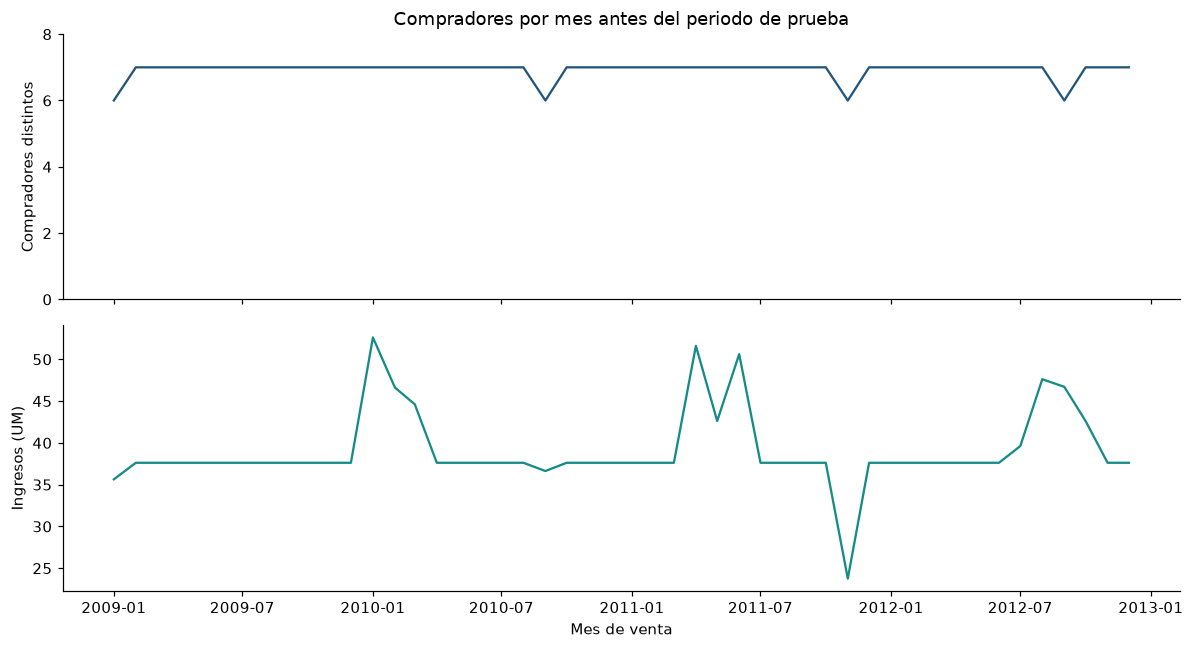

In [298]:
import matplotlib
import matplotlib.pyplot as plt

print(f"Matplotlib {matplotlib.__version__}")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
mensual_desarrollo = resumen_mensual.loc[resumen_mensual.index.year < ANIO_INICIO_PRUEBA_PROPUESTO]
fig, ejes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
fechas = mensual_desarrollo.index.to_timestamp()
ejes[0].plot(fechas, mensual_desarrollo["Compradores"], color="#24557A")
ejes[0].set_ylabel("Compradores distintos")
ejes[0].set_ylim(0, 8)
ejes[0].set_yticks(range(0, 9, 2))
ejes[0].set_title("Compradores por mes antes del periodo de prueba")
ejes[1].plot(fechas, mensual_desarrollo["IngresosUM"], color="#168B87")
ejes[1].set_ylabel("Ingresos (UM)")
ejes[1].set_xlabel("Mes de venta")
fig.tight_layout()
fig.savefig(ruta_figuras / "eda_compras_mensuales.png", dpi=160, bbox_inches="tight")
plt.show()


### 5. Construcción de la etiqueta de recompra

Para cada cliente que compró en el mes de corte, se busca su presencia en el
mes calendario siguiente. Se usa una unión de claves únicas cliente-mes.
El último mes de resultado admitido se controla en la configuración.
Diciembre de 2013 como mes de corte requeriría observar enero de 2014.

El cociente de positivos entre compradores de una cohorte reconstruye el KPI-04
del mes de resultado. Los conteos acompañan las tasas porque cada cohorte es
pequeña. La frecuencia global de la etiqueta pondera por compradores de cada
cohorte, mientras que el tablero presenta un porcentaje para cada mes.


In [299]:
cohortes = compras_cliente_mes[["MesVenta", "IdCliente"]].rename(columns={"MesVenta": "MesCorte"})
cohortes["MesResultado"] = cohortes["MesCorte"] + 1
cohortes = cohortes.loc[cohortes["MesResultado"] <= ULTIMO_MES_RESULTADO_COMPLETO].copy()

presencia_siguiente = compras_cliente_mes[["MesVenta", "IdCliente"]].rename(columns={"MesVenta": "MesResultado"})
presencia_siguiente["RecompraMesSiguiente"] = 1
cohortes = cohortes.merge(presencia_siguiente, on=["MesResultado", "IdCliente"],
                          how="left", validate="one_to_one")
cohortes["RecompraMesSiguiente"] = cohortes["RecompraMesSiguiente"].fillna(0).astype("int8")
cohortes = cohortes.sort_values(["MesCorte", "IdCliente"]).reset_index(drop=True)

kpi_retencion = cohortes.groupby("MesResultado").agg(
    CompradoresMesAnterior=("IdCliente", "size"),
    ClientesRetenidos=("RecompraMesSiguiente", "sum"),
)
kpi_retencion["KPI04_RetencionPct"] = 100 * kpi_retencion["ClientesRetenidos"] / kpi_retencion["CompradoresMesAnterior"]
assert cohortes["RecompraMesSiguiente"].isin([0, 1]).all()
assert not cohortes.duplicated(["IdCliente", "MesCorte"]).any()
assert len(cohortes) == kpi_retencion["CompradoresMesAnterior"].sum()

cohortes_desarrollo = cohortes.loc[cohortes["MesResultado"].dt.year < ANIO_INICIO_PRUEBA_PROPUESTO]
distribucion_desarrollo = cohortes_desarrollo["RecompraMesSiguiente"].value_counts().reindex([0, 1], fill_value=0).to_frame("Casos")
distribucion_desarrollo["Porcentaje"] = 100 * distribucion_desarrollo["Casos"] / len(cohortes_desarrollo)
display(distribucion_desarrollo)
print(f"Casos con desenlace observable: {len(cohortes)}")
print(f"Casos anteriores a {ANIO_INICIO_PRUEBA_PROPUESTO}: {len(cohortes_desarrollo)}")
print(f"Casos reservables desde {ANIO_INICIO_PRUEBA_PROPUESTO}: {len(cohortes) - len(cohortes_desarrollo)}")
display(kpi_retencion.loc[kpi_retencion.index.year < ANIO_INICIO_PRUEBA_PROPUESTO].head())


,Casos,Porcentaje
RecompraMesSiguiente,,
0,292,89.846154
1,33,10.153846


Casos con desenlace observable: 405
Casos anteriores a 2013: 325
Casos reservables desde 2013: 80


,CompradoresMesAnterior,ClientesRetenidos,KPI04_RetencionPct
MesResultado,,,
2009-02,6,1,16.666667
2009-03,7,1,14.285714
2009-04,7,1,14.285714
2009-05,7,1,14.285714
2009-06,7,1,14.285714


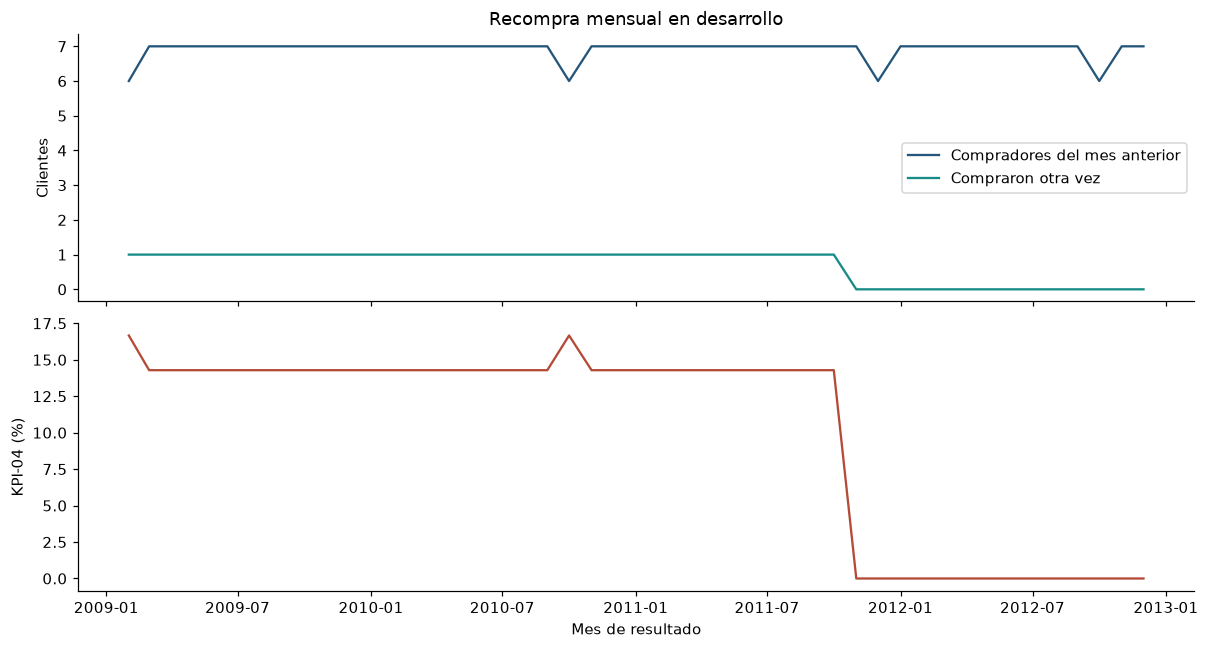

In [300]:
retencion_desarrollo = kpi_retencion.loc[kpi_retencion.index.year < ANIO_INICIO_PRUEBA_PROPUESTO]
fig, ejes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
fechas = retencion_desarrollo.index.to_timestamp()
ejes[0].plot(fechas, retencion_desarrollo["CompradoresMesAnterior"], label="Compradores del mes anterior", color="#24557A")
ejes[0].plot(fechas, retencion_desarrollo["ClientesRetenidos"], label="Compraron otra vez", color="#168B87")
ejes[0].set_ylabel("Clientes")
ejes[0].set_title("Recompra mensual en desarrollo")
ejes[0].legend()
ejes[1].plot(fechas, retencion_desarrollo["KPI04_RetencionPct"], color="#B34B37")
ejes[1].set_ylabel("KPI-04 (%)")
ejes[1].set_xlabel("Mes de resultado")
fig.tight_layout()
fig.savefig(ruta_figuras / "eda_retencion_mensual.png", dpi=160, bbox_inches="tight")
plt.show()


### 6. Ejemplo rastreable a las ventas originales

En enero de 2009 compraron seis clientes. Solo el cliente 2 vuelve en febrero.
La cohorte de enero aporta seis ejemplos, uno positivo y cinco negativos.
El KPI-04 de febrero es 1/6 = 16,67 %. La tabla siguiente muestra ese cruce y
las líneas originales del cliente 2 que permiten comprobarlo.


In [301]:
ejemplo_enero = cohortes.loc[cohortes["MesCorte"] == pd.Period("2009-01", "M")].copy()
display(ejemplo_enero)
display(ventas.loc[
    ventas["IdCliente"].eq(2) & ventas["MesVenta"].isin(pd.period_range("2009-01", "2009-02", freq="M")),
    ["IdLineaFactura", "IdFactura", "IdCliente", "FechaFactura", "Cantidad", "ImporteLinea"],
])
assert len(ejemplo_enero) == 6
assert ejemplo_enero["RecompraMesSiguiente"].sum() == 1
assert ejemplo_enero.loc[ejemplo_enero["RecompraMesSiguiente"].eq(1), "IdCliente"].tolist() == [2]
assert np.isclose(kpi_retencion.loc[pd.Period("2009-02", "M"), "KPI04_RetencionPct"], 100 / 6)


,MesCorte,IdCliente,MesResultado,RecompraMesSiguiente
0,2009-01,2,2009-02,1
1,2009-01,4,2009-02,0
2,2009-01,8,2009-02,0
3,2009-01,14,2009-02,0
4,2009-01,23,2009-02,0
5,2009-01,37,2009-02,0


,IdLineaFactura,IdFactura,IdCliente,FechaFactura,Cantidad,ImporteLinea
0,1,1,2,2009-01-01,1,0.99
1,2,1,2,2009-01-01,1,0.99
59,60,12,2,2009-02-11,1,0.99
60,61,12,2,2009-02-11,1,0.99
61,62,12,2,2009-02-11,1,0.99
62,63,12,2,2009-02-11,1,0.99
63,64,12,2,2009-02-11,1,0.99
64,65,12,2,2009-02-11,1,0.99
65,66,12,2,2009-02-11,1,0.99
66,67,12,2,2009-02-11,1,0.99


### 7. Variables conocidas al cierre del mes

Se calculan medidas de recencia, frecuencia, gasto y diversidad con una ventana
de **90 días calendario**, cuyo extremo derecho es el primer día del siguiente
mes, excluido. La recencia usa días completos desde la última compra hasta la
fecha de corte. La antigüedad se mide desde la primera compra que aparece en el
extracto. El país corresponde a la última venta observada hasta ese cierre.

El comienzo del archivo limita la historia disponible. `DiasVentanaObservados`
registra cuántos de los 90 días están cubiertos por el extracto.
`AntiguedadObservadaDias` permite distinguir clientes recién observados.
La cobertura del historial se adopta de las exportaciones originales del
workshop, conciliadas con el CSV procesado hasta diciembre de 2013.

La función recibe solo ventas y las claves de los casos. La etiqueta se adjunta
después del cálculo de los predictores. Los precios normalizados, los indicadores
del workshop y `CategoriaPrecio` se mantienen en el CSV fuente para trazabilidad.
La lista explícita de predictores para Jeremy aparece al final de esta fase.


In [302]:
def construir_predictores(ventas_fuente, claves):
    inicio_extracto = ventas_fuente["FechaFactura"].min().normalize()
    filas = []
    for mes, grupo in claves.groupby("MesCorte", sort=True):
        fin_exclusivo = (mes + 1).start_time
        fecha_corte = fin_exclusivo - pd.Timedelta(days=1)
        inicio_ventana = fin_exclusivo - pd.Timedelta(days=VENTANA_DIAS)
        historia = ventas_fuente.loc[ventas_fuente["FechaFactura"] < fin_exclusivo]
        reciente = historia.loc[historia["FechaFactura"] >= inicio_ventana]
        medidas = reciente.groupby("IdCliente").agg(
            Facturas90d=("IdFactura", "nunique"),
            Gasto90dUM=("ImporteLinea", "sum"),
            Unidades90d=("Cantidad", "sum"),
            Generos90d=("IdGenero", "nunique"),
        )
        ultima = historia.sort_values(["FechaFactura", "IdLineaFactura"]).groupby("IdCliente").tail(1).set_index("IdCliente")
        primera = historia.groupby("IdCliente")["FechaFactura"].min()
        bloque = grupo[["IdCliente", "MesCorte", "MesResultado"]].set_index("IdCliente").join(medidas)
        bloque["FechaCorte"] = fecha_corte
        bloque["RecenciaDias"] = (fecha_corte - ultima["FechaFactura"].dt.normalize()).dt.days
        bloque["AntiguedadObservadaDias"] = (fecha_corte - primera.dt.normalize()).dt.days
        bloque["DiasVentanaObservados"] = (fin_exclusivo - max(inicio_ventana, inicio_extracto)).days
        bloque["PaisCliente"] = ultima["PaisCliente"]
        filas.append(bloque.reset_index())
    return pd.concat(filas, ignore_index=True).sort_values(["MesCorte", "IdCliente"]).reset_index(drop=True)

predictores_candidatos = construir_predictores(ventas, cohortes[["IdCliente", "MesCorte", "MesResultado"]])
datos_cliente_mes = predictores_candidatos.merge(
    cohortes[["IdCliente", "MesCorte", "RecompraMesSiguiente"]],
    on=["IdCliente", "MesCorte"], how="left", validate="one_to_one",
)
assert len(datos_cliente_mes) == len(cohortes)
assert datos_cliente_mes.notna().all().all()
assert datos_cliente_mes["RecenciaDias"].between(0, 30).all()
assert datos_cliente_mes["DiasVentanaObservados"].between(1, VENTANA_DIAS).all()
display(datos_cliente_mes.head(6))


,IdCliente,MesCorte,MesResultado,Facturas90d,Gasto90dUM,Unidades90d,Generos90d,FechaCorte,RecenciaDias,AntiguedadObservadaDias,DiasVentanaObservados,PaisCliente,RecompraMesSiguiente
0,2,2009-01,2009-02,1,1.98,2,1,2009-01-31,30,30,31,Germany,1
1,4,2009-01,2009-02,1,3.96,4,1,2009-01-31,29,29,31,Norway,0
2,8,2009-01,2009-02,1,5.94,6,1,2009-01-31,28,28,31,Belgium,0
3,14,2009-01,2009-02,1,8.91,9,3,2009-01-31,25,25,31,Canada,0
4,23,2009-01,2009-02,1,13.86,14,6,2009-01-31,20,20,31,USA,0
5,37,2009-01,2009-02,1,0.99,1,1,2009-01-31,12,12,31,Germany,0


### 8. Atípicos, variabilidad y correlaciones

Se estudian los predictores en el bloque inicial con resultados de **2009**.
Ese bloque es anterior a los años de validación y prueba propuestos. Los límites
IQR se calculan sobre ese bloque. Una observación fuera de los límites se marca
para revisar su significado. En frecuencia y cobertura, IQR vale cero y las desviaciones se marcan aunque sean observaciones válidas. Se conservan los importes, las cantidades y los
clientes válidos. Las sumas siguen conciliando con el CSV fuente.

Se comparan Pearson y Spearman y se muestran la cardinalidad y la variabilidad
para identificar campos redundantes. Los identificadores se usan como claves.
Las fechas delimitan las ventanas y los bloques temporales.


In [303]:
columnas_numericas_candidatas = [
    "RecenciaDias", "Facturas90d", "Gasto90dUM", "Unidades90d", "Generos90d",
    "AntiguedadObservadaDias", "DiasVentanaObservados",
]
eda_inicial = datos_cliente_mes.loc[
    datos_cliente_mes["MesResultado"].dt.year <= ANIO_FIN_ENTRENAMIENTO_INICIAL
].copy()
assert eda_inicial["MesResultado"].dt.year.max() < ANIO_INICIO_PRUEBA_PROPUESTO
resumen_predictores = eda_inicial[columnas_numericas_candidatas].describe().T
resumen_predictores["ValoresDistintos"] = eda_inicial[columnas_numericas_candidatas].nunique()
display(resumen_predictores.round(3))

q1 = eda_inicial[columnas_numericas_candidatas].quantile(0.25)
q3 = eda_inicial[columnas_numericas_candidatas].quantile(0.75)
iqr = q3 - q1
limites_iqr = pd.DataFrame({"Q1": q1, "Q3": q3, "IQR": iqr,
                            "LimiteInferior": q1 - 1.5 * iqr, "LimiteSuperior": q3 + 1.5 * iqr})
marcas_atipicos = (
    eda_inicial[columnas_numericas_candidatas].lt(limites_iqr["LimiteInferior"], axis="columns")
    | eda_inicial[columnas_numericas_candidatas].gt(limites_iqr["LimiteSuperior"], axis="columns")
)
limites_iqr["CasosMarcados"] = marcas_atipicos.sum()
limites_iqr["PorcentajeMarcado"] = 100 * marcas_atipicos.mean()
display(limites_iqr.round(3))

columnas_correlacion = [c for c in columnas_numericas_candidatas if eda_inicial[c].nunique() > 1]
pearson = eda_inicial[columnas_correlacion].corr(method="pearson")
# Correlacionar rangos permite calcular Spearman con pandas y NumPy.
spearman = eda_inicial[columnas_correlacion].rank().corr(method="pearson")
display(pearson.round(3))
display(spearman.round(3))
print("Correlación gasto/unidades:", round(pearson.loc["Gasto90dUM", "Unidades90d"], 4))


,count,mean,std,min,25%,50%,75%,max,ValoresDistintos
RecenciaDias,76.0,20.368,6.452,5.00,16.75,23.00,25.00,30.00,24
Facturas90d,76.0,1.132,0.340,1.00,1.00,1.00,1.00,2.00,2
Gasto90dUM,76.0,5.679,4.867,0.99,1.98,3.96,8.91,15.84,8
Unidades90d,76.0,5.737,4.916,1.00,2.00,4.00,9.00,16.00,7
Generos90d,76.0,1.934,1.398,1.00,1.00,1.00,2.00,6.00,6
AntiguedadObservadaDias,76.0,73.434,82.217,7.00,24.00,27.00,117.00,332.00,33
DiasVentanaObservados,76.0,82.487,17.634,31.00,90.00,90.00,90.00,90.00,3


,Q1,Q3,IQR,LimiteInferior,LimiteSuperior,CasosMarcados,PorcentajeMarcado
RecenciaDias,16.75,25.00,8.25,4.375,37.375,0,0.000
Facturas90d,1.00,1.00,0.00,1.000,1.000,10,13.158
Gasto90dUM,1.98,8.91,6.93,-8.415,19.305,0,0.000
Unidades90d,2.00,9.00,7.00,-8.500,19.500,0,0.000
Generos90d,1.00,2.00,1.00,-0.500,3.500,12,15.789
AntiguedadObservadaDias,24.00,117.00,93.00,-115.500,256.500,4,5.263
DiasVentanaObservados,90.00,90.00,0.00,90.000,90.000,13,17.105


,RecenciaDias,Facturas90d,Gasto90dUM,Unidades90d,Generos90d,AntiguedadObservadaDias,DiasVentanaObservados
RecenciaDias,1.000,-0.314,-0.139,-0.139,-0.226,-0.269,-0.189
Facturas90d,-0.314,1.000,0.818,0.818,0.775,-0.082,0.098
Gasto90dUM,-0.139,0.818,1.000,1.000,0.923,0.027,-0.014
Unidades90d,-0.139,0.818,1.000,1.000,0.923,0.027,-0.014
Generos90d,-0.226,0.775,0.923,0.923,1.000,-0.025,-0.019
AntiguedadObservadaDias,-0.269,-0.082,0.027,0.027,-0.025,1.000,0.252
DiasVentanaObservados,-0.189,0.098,-0.014,-0.014,-0.019,0.252,1.000


,RecenciaDias,Facturas90d,Gasto90dUM,Unidades90d,Generos90d,AntiguedadObservadaDias,DiasVentanaObservados
RecenciaDias,1.000,-0.392,-0.118,-0.122,-0.365,-0.036,-0.246
Facturas90d,-0.392,1.000,0.596,0.596,0.632,0.196,0.081
Gasto90dUM,-0.118,0.596,1.000,1.000,0.834,0.260,-0.024
Unidades90d,-0.122,0.596,1.000,1.000,0.838,0.262,-0.016
Generos90d,-0.365,0.632,0.834,0.838,1.000,0.135,0.063
AntiguedadObservadaDias,-0.036,0.196,0.260,0.262,0.135,1.000,0.184
DiasVentanaObservados,-0.246,0.081,-0.024,-0.016,0.063,0.184,1.000


Correlación gasto/unidades: 1.0


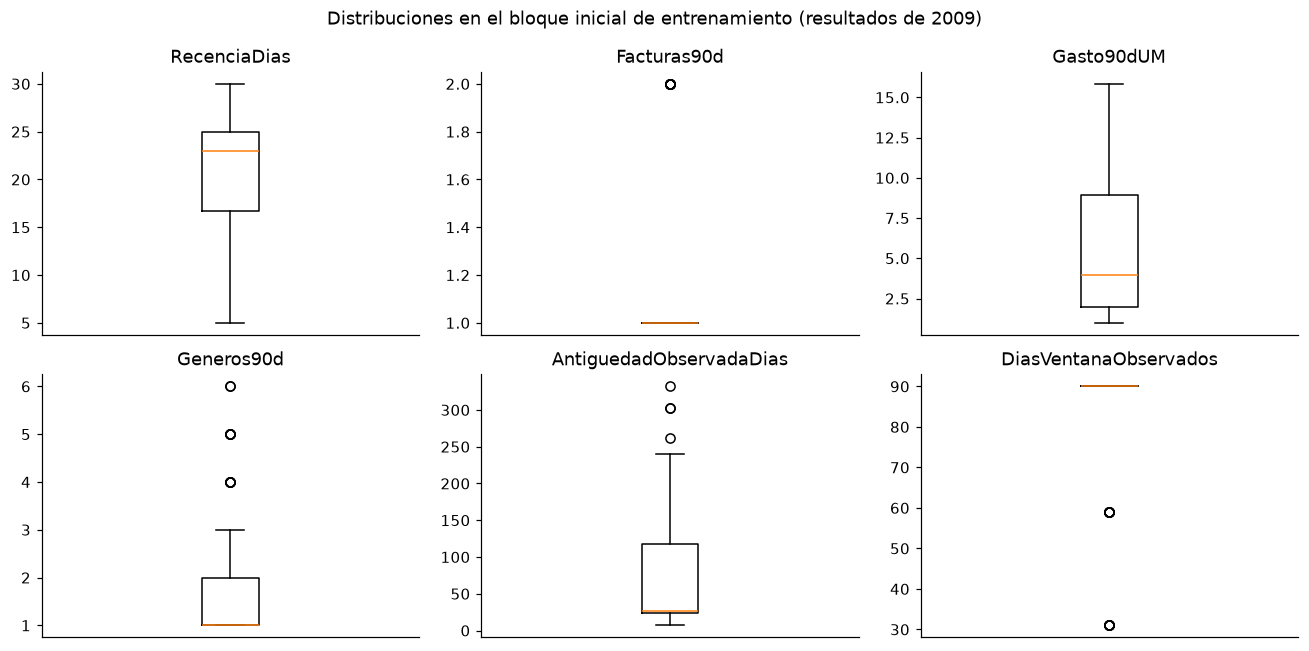

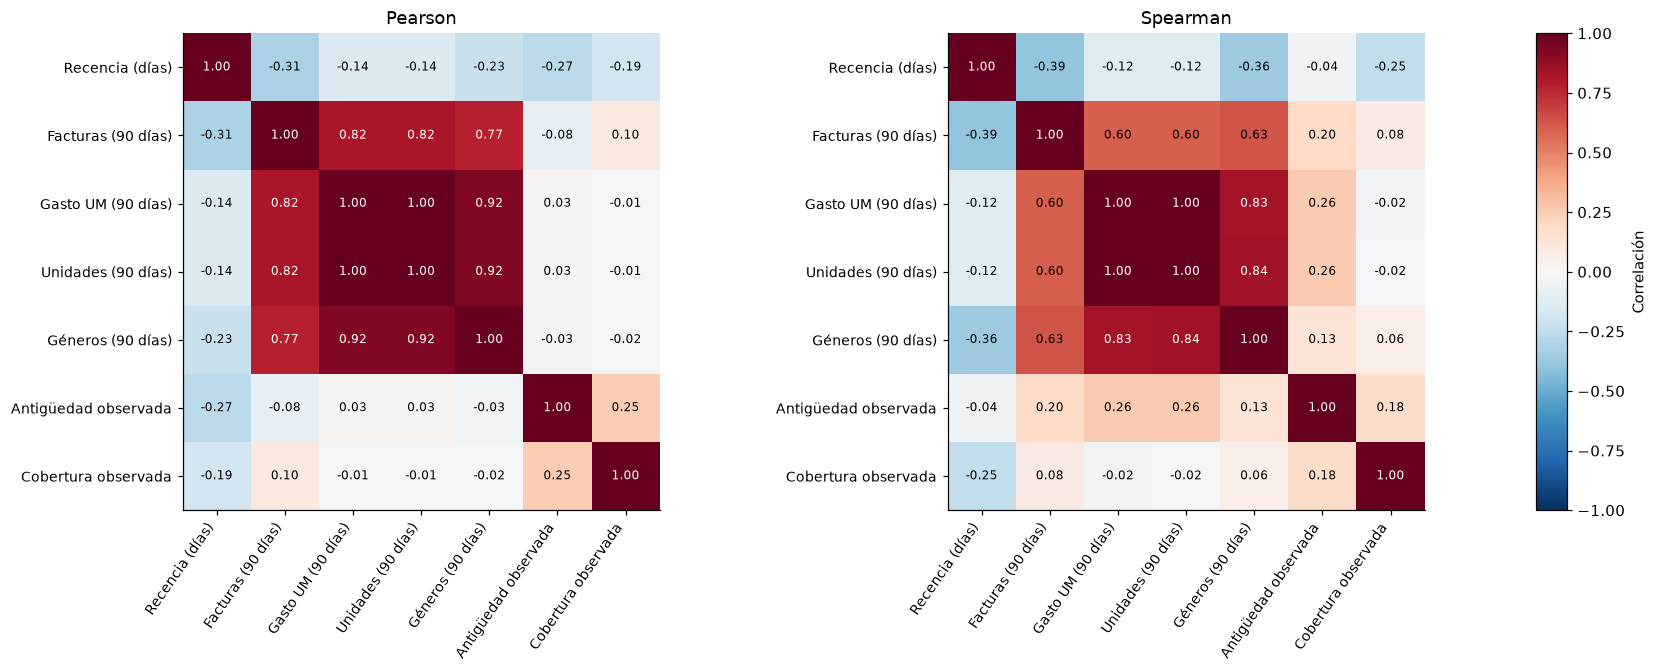

In [304]:
fig, ejes = plt.subplots(2, 3, figsize=(12, 6))
variables_boxplot = ["RecenciaDias", "Facturas90d", "Gasto90dUM", "Generos90d",
                    "AntiguedadObservadaDias", "DiasVentanaObservados"]
for eje, columna in zip(ejes.flat, variables_boxplot):
    eje.boxplot(eda_inicial[columna], orientation="vertical")
    eje.set_title(columna)
    eje.set_xticks([])
fig.suptitle("Distribuciones en el bloque inicial de entrenamiento (resultados de 2009)")
fig.tight_layout()
fig.savefig(ruta_figuras / "eda_atipicos_cliente_mes.png", dpi=160, bbox_inches="tight")
plt.show()

etiquetas = {
    "RecenciaDias": "Recencia (días)", "Facturas90d": "Facturas (90 días)",
    "Gasto90dUM": "Gasto UM (90 días)", "Unidades90d": "Unidades (90 días)",
    "Generos90d": "Géneros (90 días)",
    "AntiguedadObservadaDias": "Antigüedad observada",
    "DiasVentanaObservados": "Cobertura observada",
}
fig, ejes = plt.subplots(1, 3, figsize=(15, 6), layout="constrained",
                         gridspec_kw={"width_ratios": [1, 1, 0.045]})
for eje, matriz, titulo in zip(ejes[:2], [pearson, spearman], ["Pearson", "Spearman"]):
    imagen = eje.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
    nombres = [etiquetas[c] for c in matriz.columns]
    eje.set_xticks(range(len(matriz)), labels=nombres, rotation=55, ha="right", fontsize=9)
    eje.set_yticks(range(len(matriz)), labels=nombres, fontsize=9)
    eje.set_title(titulo)
    for i in range(len(matriz)):
        for j in range(len(matriz)):
            valor = matriz.iloc[i, j]
            eje.text(j, i, f"{valor:.2f}", ha="center", va="center",
                     fontsize=8, color="white" if abs(valor) > 0.65 else "black")
fig.colorbar(imagen, cax=ejes[2], label="Correlación")
fig.savefig(ruta_figuras / "eda_correlaciones_cliente_mes.png", dpi=160, bbox_inches="tight")
plt.show()


**Decisiones para el modelado.** Se propone un conjunto inicial de seis variables
numéricas y una categórica. `Unidades90d` queda disponible para auditoría y se
excluye de la lista inicial porque en el bloque inicial de 2009 ambas medidas tienen correlación 1. En ese bloque las unidades tienen el mismo precio. La relación debe revisarse dentro de los bloques posteriores de entrenamiento. El equipo puede
comparar otras selecciones dentro de la validación temporal de Jeremy.

La recencia se interpreta entre los compradores del mes, por lo que su rango es
menor que el de una base de todos los clientes. La antigüedad refleja la primera
aparición en el extracto y aumenta con el tiempo. La duración de la ventana
observada ayuda a identificar el inicio truncado de la fuente. Deben evaluarse
la estabilidad temporal y el posible efecto de estos dos campos en los modelos.

Para nulos nuevos, imputación, codificación de país y escalado, Jeremy construirá
un preprocesamiento ajustado en cada bloque de entrenamiento. La regresión
logística requiere escalas comparables. El árbol admite las magnitudes originales.
El desbalance se abordará con métricas de la clase positiva y parámetros elegidos
en validación. Las etiquetas de prueba se reservan para Miguel.


**Lectura del EDA para la entrega.** Los nulos y las claves no requieren
imputación ni eliminación en el CSV recibido. Las 2.240 líneas conservan un
importe total de 2.328,60 UM después de agregarse por mes. La tabla supervisada
tiene 405 oportunidades de recompra hasta diciembre de 2013.

En los 325 casos anteriores a 2013, se observan 33 recompras, aproximadamente
10,15 %. La gráfica de retención muestra que la frecuencia cambia entre meses.
En 2012 no se observan recompras en los datos disponibles. Esta variación
fundamenta la validación por bloques temporales y el análisis de falsas alarmas.

En el bloque inicial de 2009, IQR marca diez casos en `Facturas90d`, doce en
`Generos90d`, cuatro en antigüedad observada y trece en cobertura de la ventana.
El gasto y la recencia tienen cero casos marcados con este criterio. Se conservan
los registros porque sus claves, fechas e importes son coherentes con el origen.
Los límites de frecuencia y cobertura tienen IQR cero, por lo que también
marcan diferencias válidas respecto al valor más frecuente.

Los mapas de calor muestran correlación 1 entre gasto y unidades en el bloque
inicial. Se propone usar el gasto y conservar las unidades para auditoría.
La selección se revisará con entrenamiento y validación al comparar modelos.
El desempeño de clasificación se conocerá al evaluar los modelos.

**Qué puede defender Brian.** La fila final representa a un cliente comprador
en un mes concreto. Las características resumen únicamente compras conocidas
al cierre. La etiqueta consulta el mes siguiente dentro de la cobertura adoptada.
El ejemplo de enero y febrero permite comprobar las seis filas, su única recompra
y el 16,67 % del KPI-04. Las matrices de confusión y la selección del modelo se
construirán cuando Jeremy y Miguel completen sus fases.


In [305]:
predictores_numericos = [
    "RecenciaDias", "Facturas90d", "Gasto90dUM", "Generos90d",
    "AntiguedadObservadaDias", "DiasVentanaObservados",
]
predictores_categoricos = ["PaisCliente"]
columnas_predictoras = predictores_numericos + predictores_categoricos
columna_objetivo = "RecompraMesSiguiente"

diccionario = pd.DataFrame([
    ("IdCliente", "Clave", "Identificador", "Cliente del mes de corte"),
    ("MesCorte", "Control temporal", "AAAA-MM", "Mes en que el cliente compró y se emite la predicción al cierre"),
    ("MesResultado", "Control temporal", "AAAA-MM", "Mes calendario siguiente al corte"),
    ("FechaCorte", "Control temporal", "Fecha", "Último día del mes de corte"),
    ("RecenciaDias", "Predictor numérico", "Días", "Días desde última compra conocida hasta FechaCorte"),
    ("Facturas90d", "Predictor numérico", "Facturas distintas", "90 días hasta fin del mes de corte, inclusive"),
    ("Gasto90dUM", "Predictor numérico", "UM", "Suma de importes en la misma ventana de 90 días"),
    ("Unidades90d", "Auditoría", "Unidades", "Suma de cantidades en la misma ventana de 90 días. Excluida de la selección inicial"),
    ("Generos90d", "Predictor numérico", "Géneros distintos", "Diversidad de géneros en la misma ventana de 90 días"),
    ("AntiguedadObservadaDias", "Predictor numérico", "Días", "Desde primera compra registrada hasta FechaCorte. Historia truncada al inicio del extracto"),
    ("DiasVentanaObservados", "Predictor numérico", "Días", "Cobertura disponible del extracto en la ventana. Entre 1 y 90"),
    ("PaisCliente", "Predictor categórico", "País", "País en la última venta conocida al corte"),
    ("RecompraMesSiguiente", "Objetivo", "0 o 1", "1 si el cliente compra en MesResultado. 0 si ese mes es observable y no compra"),
], columns=["Variable", "Funcion", "Unidad", "DefinicionYVentana"])
assert set(diccionario["Variable"]) == set(datos_cliente_mes.columns)
assert set(columnas_predictoras).issubset(datos_cliente_mes.columns)
assert columna_objetivo not in columnas_predictoras
assert np.isfinite(datos_cliente_mes[predictores_numericos].to_numpy()).all()
display(diccionario)


,Variable,Funcion,Unidad,DefinicionYVentana
0,IdCliente,Clave,Identificador,Cliente del mes de corte
1,MesCorte,Control temporal,AAAA-MM,Mes en que el cliente compró y se emite la pre...
2,MesResultado,Control temporal,AAAA-MM,Mes calendario siguiente al corte
3,FechaCorte,Control temporal,Fecha,Último día del mes de corte
4,RecenciaDias,Predictor numérico,Días,Días desde última compra conocida hasta FechaC...
5,Facturas90d,Predictor numérico,Facturas distintas,"90 días hasta fin del mes de corte, inclusive"
6,Gasto90dUM,Predictor numérico,UM,Suma de importes en la misma ventana de 90 días
7,Unidades90d,Auditoría,Unidades,Suma de cantidades en la misma ventana de 90 d...
8,Generos90d,Predictor numérico,Géneros distintos,Diversidad de géneros en la misma ventana de 9...
9,AntiguedadObservadaDias,Predictor numérico,Días,Desde primera compra registrada hasta FechaCor...


### 9. Controles de trazabilidad y ausencia de información futura

Se comprueba cada etiqueta contra conjuntos de compradores obtenidos directamente
de las ventas, sin utilizar la unión anterior. Para tres cortes se reconstruyen
los predictores eliminando las ventas futuras. Los resultados deben coincidir.
También se comprueba que ni los datos recibidos ni el archivo de entrada cambiaron.


In [306]:
compradores_por_mes = {mes: set(g["IdCliente"]) for mes, g in ventas.groupby("MesVenta")}
etiquetas_independientes = [
    int(cliente in compradores_por_mes[mes_resultado])
    for cliente, mes_resultado in zip(datos_cliente_mes["IdCliente"], datos_cliente_mes["MesResultado"])
]
np.testing.assert_array_equal(datos_cliente_mes[columna_objetivo], etiquetas_independientes)

meses_control = [datos_cliente_mes["MesCorte"].min(), pd.Period("2011-06", "M"), datos_cliente_mes["MesCorte"].max()]
for mes_control in meses_control:
    claves_control = cohortes.loc[cohortes["MesCorte"].eq(mes_control), ["IdCliente", "MesCorte", "MesResultado"]]
    ventas_hasta_corte = ventas.loc[ventas["FechaFactura"] < (mes_control + 1).start_time]
    reconstruido = construir_predictores(ventas_hasta_corte, claves_control)
    esperado = predictores_candidatos.loc[predictores_candidatos["MesCorte"].eq(mes_control)].reset_index(drop=True)
    pd.testing.assert_frame_equal(reconstruido, esperado)

pd.testing.assert_frame_equal(ventas_originales, pd.read_csv(ruta_csv))
assert hashlib.sha256(ruta_csv.read_bytes()).hexdigest() == huella_entrada
assert (datos_cliente_mes["MesResultado"] == datos_cliente_mes["MesCorte"] + 1).all()
assert datos_cliente_mes["MesResultado"].max() == ULTIMO_MES_RESULTADO_COMPLETO
assert not datos_cliente_mes.duplicated(["IdCliente", "MesCorte"]).any()
print("Claves, importes, etiquetas y tres reconstrucciones sin ventas futuras comprobados.")


Claves, importes, etiquetas y tres reconstrucciones sin ventas futuras comprobados.


### 10. Exportación y entrega a Jeremy

El conjunto supervisado se guarda en `resultados/tablas/cliente_mes.csv` y el
diccionario en `diccionario_cliente_mes.csv`. Los meses se exportan como
`AAAA-MM`. Jeremy debe convertirlos de nuevo a periodos antes de dividir por
fecha. La tabla incluye las etiquetas reservadas para evaluación final.

La configuración actual produce **405 casos** con resultados de febrero de 2009
a diciembre de 2013. Hay **325 casos de desarrollo** antes de 2013 y **80 casos
reservables de 2013**. El conjunto completo contiene 40 recompras. En desarrollo
hay 33 recompras entre 325 casos. Predecir siempre ausencia de recompra daría
89,85 % de exactitud en ese bloque y detectaría cero positivos.

La inclusión de diciembre agrega siete compradores de noviembre y su resultado
de compra en diciembre. Un comprador de diciembre necesitaría datos de enero
de 2014 para aportar una nueva etiqueta.

El modelo tendrá que superar una referencia sencilla y sostener su desempeño en
meses posteriores. Las ventas de Chinook son datos generados de una base de
ejemplo y hay pocos casos positivos. Las recomendaciones comerciales deben
explicar el alcance académico de esta evidencia.
[Origen de los datos de Chinook](https://github.com/lerocha/chinook-database#data-sources)


In [307]:
exportacion = datos_cliente_mes.copy()
exportacion["MesCorte"] = exportacion["MesCorte"].astype(str)
exportacion["MesResultado"] = exportacion["MesResultado"].astype(str)
exportacion.to_csv(ruta_tablas / "cliente_mes.csv", index=False, date_format="%Y-%m-%d")
diccionario.to_csv(ruta_tablas / "diccionario_cliente_mes.csv", index=False)
perfil_columnas.to_csv(ruta_tablas / "eda_calidad_columnas.csv", index=False)
resumen_mensual.to_csv(ruta_tablas / "eda_resumen_mensual.csv", index=True)
kpi_retencion.to_csv(ruta_tablas / "eda_retencion_mensual.csv", index=True)
limites_iqr.to_csv(ruta_tablas / "eda_limites_iqr_2009.csv", index=True)
verificado = pd.read_csv(ruta_tablas / "cliente_mes.csv")
assert verificado.shape == datos_cliente_mes.shape
assert not verificado.duplicated(["IdCliente", "MesCorte"]).any()
assert verificado[columna_objetivo].tolist() == datos_cliente_mes[columna_objetivo].tolist()
print(f"Tabla entregada: {verificado.shape[0]} filas y {verificado.shape[1]} columnas.")
print("Predictores numéricos:", predictores_numericos)
print("Predictores categóricos:", predictores_categoricos)
print("Objetivo:", columna_objetivo)
print("Cobertura hasta diciembre de 2013 y configuración temporal documentadas en la Fase I.")


Tabla entregada: 405 filas y 13 columnas.
Predictores numéricos: ['RecenciaDias', 'Facturas90d', 'Gasto90dUM', 'Generos90d', 'AntiguedadObservadaDias', 'DiasVentanaObservados']
Predictores categóricos: ['PaisCliente']
Objetivo: RecompraMesSiguiente
Cobertura hasta diciembre de 2013 y configuración temporal documentadas en la Fase I.


### 11. Continuación del equipo

**Jeremy, Fase II.** Registrar el protocolo temporal y su semilla. La propuesta
reserva los resultados de 2013 para prueba. Para desarrollo, entrenar hasta 2009
y validar 2010, ampliar hasta 2010 y validar 2011 y ampliar hasta 2011 y validar
2012. Mantener cada mes completo en un bloque y ajustar los transformadores
dentro de cada entrenamiento. En 2012 no se observan recompras, por lo que su
ROC/AUC es indefinida. Ese bloque permite examinar falsas alarmas. Entrenar
regresión logística regularizada y árbol de profundidad limitada, comparar una
referencia mayoritaria y fijar parámetros y umbrales antes de la prueba final.

**Miguel, Fase III.** Comparar los modelos fijados sobre los mismos casos de
prueba con matriz de confusión, exactitud, curva ROC/AUC, precisión, recall y F1.
Justificar la selección y estimar la importancia de las variables. Los conteos
deben acompañar a las métricas debido al tamaño pequeño de la muestra.

**Cristopher, Fase IV.** Con los resultados obtenidos, preparar tres decisiones
de negocio sustentadas y las diapositivas para 20 minutos de exposición. Los
cuatro estudian el notebook y se preparan para las preguntas individuales.

La Fase I deja el análisis y las variables para continuar. El entrenamiento,
la comparación final y las recomendaciones se documentarán en las próximas
secciones del mismo notebook.


## Fase II. Partición temporal y entrenamiento

**Responsable: Jeremy Rodriguez Esquivel.** Jeremy asume la segunda parte y
Miguel continúa con la tercera: evaluación final, errores e importancia de variables.

Se utiliza `datos_cliente_mes`, construido por Brian, y su lista de seis
predictores numéricos y país. El objetivo continúa siendo `RecompraMesSiguiente`.
En esta fase se fijan los parámetros y umbrales de dos algoritmos y se entrenan
sus versiones finales con desarrollo. La prueba de 2013 queda para Miguel.

### 1. Protocolo definido antes de ajustar

- **Desarrollo:** resultados de febrero de 2009 a diciembre de 2012.
- **Prueba reservada:** resultados de enero a diciembre de 2013. Por ejemplo,
  predecir enero de 2013 utiliza las compras conocidas al cierre de diciembre de 2012.
- **Validación con origen creciente:** entrenar hasta 2009 y validar 2010;
  entrenar hasta 2010 y validar 2011; entrenar hasta 2011 y validar 2012.
- Cada mes completo permanece en un bloque. Un mismo cliente puede reaparecer
  en meses posteriores: el problema consiste en anticipar compras futuras de
  compradores conocidos. `IdCliente` se conserva como clave y no es predictor.
- Se usa la semilla 42. Se conserva el orden temporal en lugar de estratificar
  aleatoriamente: mezclar fechas permitiría aprender de periodos futuros.
  Se registran las clases de cada bloque y se compara `class_weight=None`
  con `class_weight="balanced"`, calculado solo con su entrenamiento.
- El criterio de ajuste es **F1 de recompra**, reuniendo las predicciones fuera
  de entrenamiento de 2010–2012. Se prueban nueve umbrales prefijados: 0,1 a 0,9.
  En empate se prefiere mayor precisión, umbral más cercano a 0,5 y el primer
  candidato de la rejilla, que favorece mayor regularización o árboles sencillos.

El año 2012 tiene una sola clase. Se conserva para medir falsas alarmas; su
ROC/AUC se registra como no definida. No se altera su distribución para producir
una métrica artificial. Este esquema respeta el uso cronológico del modelo.


In [308]:
import json
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

datos_modelado = datos_cliente_mes.sort_values(["MesResultado", "IdCliente"]).reset_index(drop=True)
es_desarrollo = datos_modelado["MesResultado"].dt.year < ANIO_INICIO_PRUEBA_PROPUESTO
desarrollo = datos_modelado.loc[es_desarrollo].copy()
prueba_reservada = datos_modelado.loc[~es_desarrollo].copy()
X_desarrollo = desarrollo[columnas_predictoras].copy()
y_desarrollo = desarrollo[columna_objetivo].copy()
X_prueba = prueba_reservada[columnas_predictoras].copy()
y_prueba = prueba_reservada[columna_objetivo].copy()  # Solo se utilizará en Fase III.

assert len(desarrollo) + len(prueba_reservada) == len(datos_modelado)
assert set(desarrollo.index).isdisjoint(prueba_reservada.index)
assert desarrollo["MesResultado"].max() < prueba_reservada["MesResultado"].min()
assert desarrollo["MesResultado"].max() <= prueba_reservada["MesCorte"].min()
assert y_desarrollo.nunique() == 2
assert set(columnas_predictoras).isdisjoint(
    {columna_objetivo, "IdCliente", "MesCorte", "MesResultado", "FechaCorte", "Unidades90d"}
)

bloques_temporales = []
resumen_bloques = []
for anio_validacion in [2010, 2011, 2012]:
    i_train = desarrollo.index[desarrollo["MesResultado"].dt.year < anio_validacion]
    i_valid = desarrollo.index[desarrollo["MesResultado"].dt.year == anio_validacion]
    train, valid = desarrollo.loc[i_train], desarrollo.loc[i_valid]
    assert len(train) and len(valid) and train[columna_objetivo].nunique() == 2
    assert set(i_train).isdisjoint(i_valid)
    assert train["MesResultado"].max() < valid["MesResultado"].min()
    assert train["MesResultado"].max() <= valid["MesCorte"].min()
    bloques_temporales.append((anio_validacion, i_train, i_valid))
    resumen_bloques.append({
        "Validacion": anio_validacion, "EntrenarHasta": str(train["MesResultado"].max()),
        "CasosTrain": len(train), "PositivosTrain": int(train[columna_objetivo].sum()),
        "CasosValidacion": len(valid), "PositivosValidacion": int(valid[columna_objetivo].sum()),
        "ROC_AUC_Definida": valid[columna_objetivo].nunique() == 2,
    })
resumen_cv = pd.DataFrame(resumen_bloques)
indices_validacion = np.concatenate([v for _, _, v in bloques_temporales])
assert len(indices_validacion) == len(set(indices_validacion))
assert set(indices_validacion).issubset(desarrollo.index)

print(f"scikit-learn {sklearn.__version__}; semilla {SEMILLA}")
print(f"Desarrollo: {len(desarrollo)} casos; {int(y_desarrollo.sum())} recompras.")
print(f"Prueba reservada: {len(X_prueba)} casos. En Fase II no se predice ni se evalúa este bloque.")
display(resumen_cv)


scikit-learn 1.9.1; semilla 42
Desarrollo: 325 casos; 33 recompras.
Prueba reservada: 80 casos. En Fase II no se predice ni se evalúa este bloque.


,Validacion,EntrenarHasta,CasosTrain,PositivosTrain,CasosValidacion,PositivosValidacion,ROC_AUC_Definida
0,2010,2009-12,76,11,83,12,True
1,2011,2010-12,159,23,83,10,True
2,2012,2011-12,242,33,83,0,False


### 2. Preparación aprendida dentro de cada entrenamiento

Se construye un `Pipeline` independiente por modelo. Las variables numéricas
usan mediana ante faltantes nuevos; país usa su valor más frecuente. Estas
medidas se aprenden únicamente del entrenamiento correspondiente. Los datos
actuales están completos; no se inventan nulos para justificar una imputación.

País se representa mediante **One-Hot Encoding**, porque sus nombres no tienen
un orden numérico. Las categorías se aprenden en entrenamiento y una categoría
nueva se admite con `handle_unknown="ignore"`. Los IDs, fechas de control y
columnas normalizadas en el workshop no entran como predictores.

- **Regresión logística:** clasificador lineal regularizado L2. `C` controla
  la intensidad inversa de regularización. Se estandarizan las seis variables
  numéricas dentro del pipeline para comparar sus escalas.
- **Árbol de decisión:** aprende reglas por umbrales e interacciones. Se
  limitan profundidad y tamaño mínimo de hoja para evitar reglas demasiado
  específicas con pocos positivos. No necesita estandarización.
- **Referencia mayoritaria:** `DummyClassifier(strategy="prior")` pronostica
  la clase más frecuente y usa como puntuación su frecuencia en entrenamiento.
  Su umbral permanece en 0,5; no se ajusta para convertirla en otro modelo.

Los modelos con pesos balanceados pueden producir puntuaciones diferentes de
las probabilidades reales de recompra. Aquí `predict_proba` se utiliza como
puntuación para clasificar; no se afirma que esté calibrada para una campaña.

[Pipelines y prevención de fuga de información](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)
· [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)


In [309]:
def crear_pipeline(clasificador, escalar):
    pasos_numericos = [("imputar", SimpleImputer(strategy="median", keep_empty_features=True))]
    if escalar:
        pasos_numericos.append(("escalar", StandardScaler()))
    categoricas = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    preparar = ColumnTransformer([
        ("numericas", Pipeline(pasos_numericos), predictores_numericos),
        ("categoricas", categoricas, predictores_categoricos),
    ], remainder="drop")
    return Pipeline([("preparar", preparar), ("modelo", clasificador)])

plantillas_modelos = {
    "RegresionLogistica": crear_pipeline(
        LogisticRegression(solver="lbfgs", max_iter=5000, random_state=SEMILLA), True),
    "ArbolDecision": crear_pipeline(DecisionTreeClassifier(random_state=SEMILLA), False),
}
rejillas_parametros = {
    "RegresionLogistica": {
        "modelo__C": [0.01, 0.1, 1.0, 10.0],
        "modelo__class_weight": [None, "balanced"],
    },
    "ArbolDecision": {
        "modelo__class_weight": [None, "balanced"],
        "modelo__max_depth": [1, 2, 3],
        "modelo__min_samples_leaf": [10, 5],
    },
}
umbrales_candidatos = np.arange(1, 10) / 10
referencia_base = DummyClassifier(strategy="prior", random_state=SEMILLA)
print("Candidatos por algoritmo:", {m: len(ParameterGrid(g)) for m, g in rejillas_parametros.items()})


Candidatos por algoritmo: {'RegresionLogistica': 8, 'ArbolDecision': 12}


### 3. Ajuste de parámetros y umbral con validación temporal

Se comparan ocho configuraciones de logística y doce del árbol. Cada una se
ajusta tres veces: siempre con meses anteriores a su bloque de validación.
La imputación, codificación, estandarización y pesos se vuelven a aprender en
cada entrenamiento. El umbral convierte una puntuación en clase: se predice
recompra cuando `puntuacion >= umbral`.

Se reúnen los 249 casos de validación de 2010–2012 y se calcula F1 con sus
conteos conjuntos; no se promedian tasas anuales con distinto denominador.
También se conserva el desglose anual para que el año 2012 no quede oculto.
Se elige una configuración por familia, sin seleccionar todavía al ganador
sobre prueba. Los resultados usados para ajustar son optimistas; su capacidad
de generalizar se comprobará en la Fase III.

[Ajuste del umbral de clasificación](https://scikit-learn.org/stable/modules/classification_threshold.html)


In [310]:
def predecir_validacion(estimador, candidato, familia, orden):
    partes = []
    for anio, i_train, i_valid in bloques_temporales:
        modelo = clone(estimador).fit(X_desarrollo.loc[i_train], y_desarrollo.loc[i_train])
        if familia == "RegresionLogistica":
            escalador = modelo.named_steps["preparar"].named_transformers_["numericas"].named_steps["escalar"]
            assert escalador.n_samples_seen_ == len(i_train)
            np.testing.assert_allclose(escalador.mean_, X_desarrollo.loc[i_train, predictores_numericos].mean())
        p = modelo.predict_proba(X_desarrollo.loc[i_valid])[:, list(modelo.classes_).index(1)]
        parte = desarrollo.loc[i_valid, ["IdCliente", "MesCorte", "MesResultado"]].copy()
        parte["IndiceCaso"] = i_valid
        parte["Real"] = y_desarrollo.loc[i_valid].to_numpy()
        parte["Puntuacion"] = p
        parte["AnioValidacion"] = anio
        parte["Familia"] = familia
        parte["Candidato"] = candidato
        parte["OrdenCandidato"] = orden
        partes.append(parte)
    return pd.concat(partes, ignore_index=True)

parametros_por_candidato = {}
predicciones_candidatos = []
for familia, rejilla in rejillas_parametros.items():
    for orden, parametros in enumerate(ParameterGrid(rejilla)):
        candidato = f"{familia}_{orden + 1:02d}"
        parametros_por_candidato[candidato] = parametros
        plantilla = clone(plantillas_modelos[familia]).set_params(**parametros)
        predicciones_candidatos.append(predecir_validacion(plantilla, candidato, familia, orden))

validacion_candidatos = pd.concat(predicciones_candidatos, ignore_index=True)
validacion_referencia = predecir_validacion(referencia_base, "Referencia", "Referencia", 0)
assert validacion_candidatos["Puntuacion"].between(0, 1).all()
assert not validacion_candidatos.duplicated(["Candidato", "IndiceCaso"]).any()
assert validacion_candidatos.groupby("Candidato").size().eq(len(indices_validacion)).all()
assert validacion_candidatos["MesResultado"].dt.year.max() < ANIO_INICIO_PRUEBA_PROPUESTO
print("Ajustes de búsqueda:", len(parametros_por_candidato) * len(bloques_temporales))
print("Casos fuera de entrenamiento por candidato:", len(indices_validacion))


Ajustes de búsqueda: 60
Casos fuera de entrenamiento por candidato: 249


In [311]:
def metricas_de_validacion(bloque, umbral):
    real = bloque["Real"].to_numpy()
    pred = (bloque["Puntuacion"].to_numpy() >= umbral).astype("int8")
    tn, fp, fn, tp = confusion_matrix(real, pred, labels=[0, 1]).ravel()
    return {
        "Casos": len(real), "Positivos": int(real.sum()), "PredichosPositivos": int(pred.sum()),
        "VN": int(tn), "FP": int(fp), "FN": int(fn), "VP": int(tp),
        "Accuracy": accuracy_score(real, pred),
        "Precision": precision_score(real, pred, zero_division=0),
        "Recall": recall_score(real, pred, zero_division=0),
        "F1": f1_score(real, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(real, bloque["Puntuacion"]) if np.unique(real).size == 2 else np.nan,
    }

filas_busqueda = []
for (familia, candidato), bloque in validacion_candidatos.groupby(["Familia", "Candidato"], sort=False):
    for umbral in umbrales_candidatos:
        filas_busqueda.append({
            "Familia": familia, "Candidato": candidato,
            "OrdenCandidato": int(bloque["OrdenCandidato"].iloc[0]), "Umbral": float(umbral),
            "DistanciaUmbral": abs(float(umbral) - 0.5),
            "Parametros": json.dumps(parametros_por_candidato[candidato], sort_keys=True),
            **metricas_de_validacion(bloque, umbral),
        })
busqueda_validacion = pd.DataFrame(filas_busqueda)
seleccion_validacion = busqueda_validacion.sort_values(
    ["Familia", "F1", "Precision", "DistanciaUmbral", "OrdenCandidato", "Umbral"],
    ascending=[True, False, False, True, True, True], kind="stable",
).drop_duplicates("Familia").reset_index(drop=True)

seleccionados = set(seleccion_validacion["Candidato"])
predicciones_validacion = pd.concat([
    validacion_candidatos.loc[validacion_candidatos["Candidato"].isin(seleccionados)],
    validacion_referencia,
], ignore_index=True)
umbrales_modelos = {r["Familia"]: float(r["Umbral"]) for _, r in seleccion_validacion.iterrows()}
umbrales_modelos["Referencia"] = 0.5

filas_anuales, filas_resumen = [], []
for familia, bloque in predicciones_validacion.groupby("Familia", sort=False):
    umbral = umbrales_modelos[familia]
    filas_resumen.append({"Familia": familia, "Umbral": umbral, **metricas_de_validacion(bloque, umbral)})
    for anio, anual in bloque.groupby("AnioValidacion"):
        filas_anuales.append({"Familia": familia, "AnioValidacion": int(anio), "Umbral": umbral,
                             **metricas_de_validacion(anual, umbral)})
resumen_validacion = pd.DataFrame(filas_resumen)
metricas_validacion_anual = pd.DataFrame(filas_anuales)
assert metricas_validacion_anual.loc[metricas_validacion_anual["AnioValidacion"].eq(2012), "ROC_AUC"].isna().all()
assert metricas_validacion_anual.loc[metricas_validacion_anual["AnioValidacion"].eq(2012), "Positivos"].eq(0).all()
print("Configuración elegida por familia; resultados exclusivamente de validación:")
display(seleccion_validacion[["Familia", "Parametros", "Umbral", "F1", "Precision", "Recall"]].round(4))
display(resumen_validacion.round(4))
display(metricas_validacion_anual.round(4))


Configuración elegida por familia; resultados exclusivamente de validación:


,Familia,Parametros,Umbral,F1,Precision,Recall
0,ArbolDecision,"{""modelo__class_weight"": null, ""modelo__max_de...",0.5,0.5484,0.4250,0.7727
1,RegresionLogistica,"{""modelo__C"": 1.0, ""modelo__class_weight"": null}",0.1,0.3048,0.1928,0.7273


,Familia,Umbral,Casos,Positivos,PredichosPositivos,VN,FP,FN,VP,Accuracy,Precision,Recall,F1,ROC_AUC
0,RegresionLogistica,0.1,249,22,83,160,67,6,16,0.7068,0.1928,0.7273,0.3048,0.6663
1,ArbolDecision,0.5,249,22,40,204,23,5,17,0.8876,0.4250,0.7727,0.5484,0.8011
2,Referencia,0.5,249,22,0,227,0,22,0,0.9116,0.0000,0.0000,0.0000,0.6994


,Familia,AnioValidacion,Umbral,Casos,Positivos,PredichosPositivos,VN,FP,FN,VP,Accuracy,Precision,Recall,F1,ROC_AUC
0,RegresionLogistica,2010,0.1,83,12,15,63,8,5,7,0.8434,0.4667,0.5833,0.5185,0.7212
1,RegresionLogistica,2011,0.1,83,10,35,47,26,1,9,0.6747,0.2571,0.9000,0.4000,0.7164
2,RegresionLogistica,2012,0.1,83,0,33,50,33,0,0,0.6024,0.0000,0.0000,0.0000,NaN
3,ArbolDecision,2010,0.5,83,12,18,61,10,4,8,0.8313,0.4444,0.6667,0.5333,0.7629
4,ArbolDecision,2011,0.5,83,10,22,60,13,1,9,0.8313,0.4091,0.9000,0.5625,0.8610
5,ArbolDecision,2012,0.5,83,0,0,83,0,0,0,1.0000,0.0000,0.0000,0.0000,NaN
6,Referencia,2010,0.5,83,12,0,71,0,12,0,0.8554,0.0000,0.0000,0.0000,0.5000
7,Referencia,2011,0.5,83,10,0,73,0,10,0,0.8795,0.0000,0.0000,0.0000,0.5000
8,Referencia,2012,0.5,83,0,0,83,0,0,0,1.0000,0.0000,0.0000,0.0000,NaN


### 4. Evidencia gráfica del entrenamiento y del ajuste

La primera figura muestra que cada entrenamiento se amplía con el pasado y
que 2013 permanece reservado. La segunda permite observar cómo cambia F1 con
el umbral para la configuración elegida de cada algoritmo. La línea vertical
identifica el umbral que se entregará a Miguel. Ninguna figura contiene
predicciones o métricas de prueba.


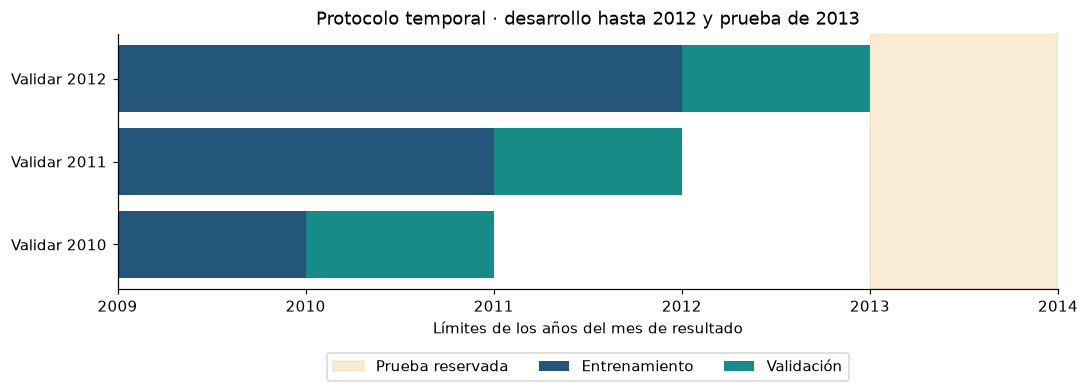

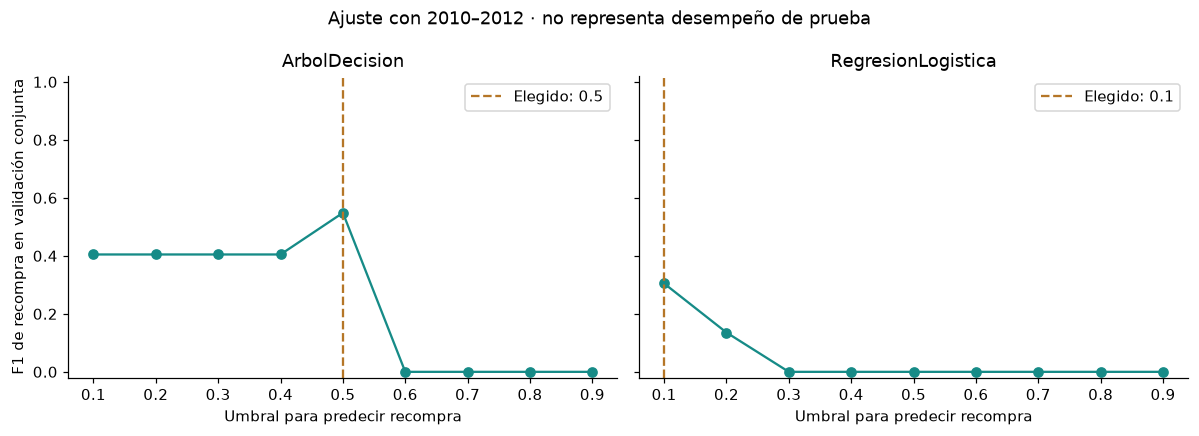

In [312]:
fig, eje = plt.subplots(figsize=(10, 3.8))
for fila, (anio, _, _) in enumerate(bloques_temporales):
    eje.barh(fila, anio - 2009, left=2009, color="#24557A", label="Entrenamiento" if fila == 0 else None)
    eje.barh(fila, 1, left=anio, color="#168B87", label="Validación" if fila == 0 else None)
eje.axvspan(2013, 2014, color="#E8B75B", alpha=0.25, label="Prueba reservada")
eje.set_yticks(range(3), [f"Validar {a}" for a, _, _ in bloques_temporales])
eje.set_xticks(range(2009, 2015))
eje.set_xlim(2009, 2014)
eje.set_xlabel("Límites de los años del mes de resultado")
eje.set_title("Protocolo temporal · desarrollo hasta 2012 y prueba de 2013")
eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)
fig.tight_layout()
fig.savefig(ruta_figuras / "fase2_particion_temporal.png", bbox_inches="tight")
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for eje, (_, elegido) in zip(ejes, seleccion_validacion.iterrows()):
    curva = busqueda_validacion.loc[busqueda_validacion["Candidato"].eq(elegido["Candidato"])].sort_values("Umbral")
    eje.plot(curva["Umbral"], curva["F1"], marker="o", color="#168B87")
    eje.axvline(elegido["Umbral"], color="#B57627", linestyle="--", label=f"Elegido: {elegido['Umbral']:.1f}")
    eje.set_title(elegido["Familia"])
    eje.set_xlabel("Umbral para predecir recompra")
    eje.set_ylim(-0.02, 1.02)
    eje.legend()
ejes[0].set_ylabel("F1 de recompra en validación conjunta")
fig.suptitle("Ajuste con 2010–2012 · no representa desempeño de prueba")
fig.tight_layout()
fig.savefig(ruta_figuras / "fase2_ajuste_umbrales.png", bbox_inches="tight")
plt.show()


### 5. Entrenamiento final y controles de preparación

Los parámetros y umbrales ya están fijados. Cada modelo final se ajusta con
los 325 casos de desarrollo. Su transformación se vuelve a aprender con esos
casos. `X_prueba` y `y_prueba` quedan disponibles para la Fase III, sin
participar en el ajuste o en la elección del umbral.

También se conservan versiones por bloque en `modelos_validacion`. Si Miguel
explora importancia sobre validación, debe usar el modelo entrenado con el
pasado de ese bloque; el modelo final ya fue ajustado con todos los años de
desarrollo. Las importancias y la comparación final corresponden a su fase.

Se comprueban la mediana, la media y las categorías realmente aprendidas con
desarrollo. Un caso de control sintético con un país nuevo y un faltante
verifica el transformador sin modificar los datos originales.


In [313]:
modelos_ajustados = {"Referencia": clone(referencia_base).fit(X_desarrollo, y_desarrollo)}
modelos_validacion = {}
for _, elegido in seleccion_validacion.iterrows():
    familia = elegido["Familia"]
    parametros = parametros_por_candidato[elegido["Candidato"]]
    plantilla = clone(plantillas_modelos[familia]).set_params(**parametros)
    modelos_ajustados[familia] = clone(plantilla).fit(X_desarrollo, y_desarrollo)
    modelos_validacion[familia] = {
        anio: clone(plantilla).fit(X_desarrollo.loc[i_train], y_desarrollo.loc[i_train])
        for anio, i_train, _ in bloques_temporales
    }

for familia in plantillas_modelos:
    preparar = modelos_ajustados[familia].named_steps["preparar"]
    numericas = preparar.named_transformers_["numericas"]
    np.testing.assert_allclose(numericas.named_steps["imputar"].statistics_, X_desarrollo[predictores_numericos].median())
    codificador = preparar.named_transformers_["categoricas"].named_steps["codificar"]
    assert set(codificador.categories_[0]) == set(X_desarrollo["PaisCliente"])
    if familia == "RegresionLogistica":
        np.testing.assert_allclose(numericas.named_steps["escalar"].mean_, X_desarrollo[predictores_numericos].mean())
    control = X_desarrollo.iloc[[0]].copy()
    control[predictores_numericos] = control[predictores_numericos].astype(float)
    control["PaisCliente"] = control["PaisCliente"].astype(object)
    control.loc[:, "PaisCliente"] = "PAIS_NUEVO_CONTROL"
    control.loc[:, predictores_numericos[0]] = np.nan
    assert np.isfinite(preparar.transform(control)).all()
    assert len(preparar.get_feature_names_out()) == preparar.transform(X_desarrollo.iloc[[0]]).shape[1]

assert hashlib.sha256(ruta_csv.read_bytes()).hexdigest() == huella_entrada
print("Modelos finales entrenados solo con desarrollo:", list(modelos_ajustados))
print("Umbrales fijados en validación:", umbrales_modelos)
print("Medianas, medias, categorías y caso nuevo comprobados. Prueba pendiente de Fase III.")


Modelos finales entrenados solo con desarrollo: ['Referencia', 'ArbolDecision', 'RegresionLogistica']
Umbrales fijados en validación: {'ArbolDecision': 0.5, 'RegresionLogistica': 0.1, 'Referencia': 0.5}
Medianas, medias, categorías y caso nuevo comprobados. Prueba pendiente de Fase III.


### 6. Entrega a Miguel para la Fase III

| Objeto disponible después de Run All | Uso |
| --- | --- |
| `modelos_ajustados` | Referencia, logística y árbol, ajustados con desarrollo. |
| `umbrales_modelos` | Umbral elegido por familia; usarlo con `predict_proba`, no sustituirlo por el 0,5 de `predict`. |
| `X_prueba`, `y_prueba` | Los mismos 80 casos de 2013 para comparar los tres métodos. |
| `prueba_reservada` | Claves cliente-mes para rastrear cada predicción final. |
| `seleccion_validacion` | Parámetros, umbrales y criterio que quedaron fijados antes de la prueba. |
| `predicciones_validacion` | Predicciones fuera de entrenamiento de 2010–2012, incluida la referencia. |
| `modelos_validacion`, `bloques_temporales` | Modelos y filas de cada bloque, para interpretar predicciones sobre periodos no usados en su entrenamiento. |

Miguel calculará matrices de confusión, accuracy, ROC/AUC, precisión, recall y
F1 sobre prueba. Comparará errores, seleccionará el modelo y analizará variables
relevantes. Los resultados de prueba no deben usarse después para cambiar
parámetros o umbrales y presentar esos mismos casos como evaluación independiente.

Los archivos `fase2_*` se reconstruyen al ejecutar el notebook. Los modelos
permanecen como objetos de Python: el equipo ejecuta Run All para obtenerlos;
no hace falta descargar modelos serializados ni acceder a PostgreSQL.


In [314]:
particion_fase2 = datos_modelado[["IdCliente", "MesCorte", "MesResultado"]].copy()
particion_fase2["Particion"] = np.where(es_desarrollo, "Desarrollo", "PruebaReservada")
for columna in ["MesCorte", "MesResultado"]:
    particion_fase2[columna] = particion_fase2[columna].astype(str)
particion_fase2.to_csv(ruta_tablas / "fase2_particion_cliente_mes.csv", index=False)
resumen_cv.to_csv(ruta_tablas / "fase2_bloques_temporales.csv", index=False)
busqueda_validacion.to_csv(ruta_tablas / "fase2_busqueda_validacion.csv", index=False)
seleccion_validacion.to_csv(ruta_tablas / "fase2_configuraciones_elegidas.csv", index=False)
resumen_validacion.to_csv(ruta_tablas / "fase2_resumen_validacion.csv", index=False)
metricas_validacion_anual.to_csv(ruta_tablas / "fase2_validacion_anual.csv", index=False)
predicciones_validacion.to_csv(ruta_tablas / "fase2_predicciones_validacion.csv", index=False)

protocolo_fase2 = {
    "responsable": "Jeremy Rodriguez Esquivel", "siguiente_fase": "Miguel / Fase III",
    "semilla": SEMILLA, "sha256_entrada": huella_entrada,
    "objetivo": columna_objetivo, "predictores": columnas_predictoras,
    "desarrollo": {"desde": str(desarrollo["MesResultado"].min()),
                   "hasta": str(desarrollo["MesResultado"].max()), "casos": len(desarrollo)},
    "prueba": {"desde": str(prueba_reservada["MesResultado"].min()),
               "hasta": str(prueba_reservada["MesResultado"].max()), "casos": len(X_prueba),
               "predicha_en_fase2": False, "evaluada_en_fase2": False},
    "validaciones": [int(a) for a, _, _ in bloques_temporales],
    "criterio": "F1 positivo conjunto en validacion temporal 2010-2012",
    "desempate": "Precision mayor; umbral mas cercano a 0.5; orden de rejilla; umbral menor",
    "estratificacion": "Se conserva la cronologia y cada mes completo; sin reparto aleatorio de fechas",
    "rejillas": rejillas_parametros, "umbrales_candidatos": umbrales_candidatos.tolist(),
    "umbrales_elegidos": umbrales_modelos,
    "parametros_elegidos": {r["Familia"]: parametros_por_candidato[r["Candidato"]]
                            for _, r in seleccion_validacion.iterrows()},
    "versiones": {"python": platform.python_version(), "pandas": pd.__version__,
                  "numpy": np.__version__, "matplotlib": matplotlib.__version__,
                  "scikit-learn": sklearn.__version__},
}
(ruta_tablas / "fase2_protocolo.json").write_text(
    json.dumps(protocolo_fase2, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Fase II exportada: protocolo, partición, búsqueda y resultados de validación; dos figuras.")
print("La evaluación final de 2013 y la selección del ganador continúan con Miguel.")


Fase II exportada: protocolo, partición, búsqueda y resultados de validación; dos figuras.
La evaluación final de 2013 y la selección del ganador continúan con Miguel.


### 7. Lectura del ajuste y límites

La búsqueda eligió logística con `C=1`, sin pesos y umbral **0,1**, y un
árbol de profundidad máxima **2**, mínimo **10** casos por hoja, sin pesos
y umbral **0,5**. La regularización y las restricciones del árbol se
compararon con alternativas dentro de desarrollo; esos valores no se
eligieron consultando 2013.

Sobre los 249 casos de validación, con 22 recompras, logística detectó
16 y produjo 67 falsas alarmas: F1 ≈ **0,3048**. El árbol detectó 17 y
produjo 23 falsas alarmas: F1 ≈ **0,5484**. La referencia mayoritaria no
detectó recompras. La tabla anual permite revisar la ausencia de positivos
de 2012 y evita interpretar su accuracy como evidencia suficiente.

Estas cifras orientan el ajuste. El mismo conjunto de validación se usó
para escoger parámetros y umbral, por lo que la tabla no constituye una
estimación independiente del desempeño futuro. Hay pocos positivos y
ventas de demostración; la selección final y sus límites se argumentarán
con la prueba reservada en la Fase III de Miguel.


In [315]:

print("Modelos:", list(modelos_ajustados))
print("Umbrales:", umbrales_modelos)
print("Casos de prueba:", len(X_prueba))
print("Etiquetas de prueba:", len(y_prueba))

Modelos: ['Referencia', 'ArbolDecision', 'RegresionLogistica']
Umbrales: {'ArbolDecision': 0.5, 'RegresionLogistica': 0.1, 'Referencia': 0.5}
Casos de prueba: 80
Etiquetas de prueba: 80


## Fase III · Evaluación

### Comparación en la prueba de 2013

Se evalúan la referencia mayoritaria, la regresión logística y el árbol de decisión sobre los mismos 80 casos cliente-mes de 2013. De esos casos, 7 corresponden a recompras observadas.

Se aplican los umbrales fijados en la Fase II. Para calcular ROC/AUC se usan las probabilidades de recompra. Para las demás métricas se usan las clases asignadas con cada umbral. Si un modelo no emite alertas, su precisión se reporta como 0 por convención.

In [316]:
nombres_evaluacion = {
    "Referencia": "Referencia mayoritaria",
    "RegresionLogistica": "Regresión logística",
    "ArbolDecision": "Árbol de decisión",
}

assert X_prueba.index.equals(y_prueba.index)

filas_evaluacion = []

for familia, nombre in nombres_evaluacion.items():
    modelo = modelos_ajustados[familia]
    umbral = umbrales_modelos[familia]

    indice_recompra = list(modelo.classes_).index(1)
    probabilidades = modelo.predict_proba(X_prueba)[:, indice_recompra]

    casos_evaluados = pd.DataFrame({
        "Real": y_prueba,
        "Puntuacion": probabilidades,
    })
    metricas = metricas_de_validacion(casos_evaluados, umbral)

    filas_evaluacion.append({
        "Modelo": nombre,
        "Umbral": umbral,
        "Exactitud": metricas["Accuracy"],
        "Precisión": metricas["Precision"],
        "Recall": metricas["Recall"],
        "F1": metricas["F1"],
        "ROC/AUC": metricas["ROC_AUC"],
        "Recompras detectadas": metricas["VP"],
        "Recompras perdidas": metricas["FN"],
        "Falsas alarmas": metricas["FP"],
        "Aciertos sin recompra": metricas["VN"],
        "Alertas totales": metricas["VP"] + metricas["FP"],
    })

comparacion_prueba = pd.DataFrame(filas_evaluacion)

comparacion_prueba.to_csv(
    ruta_tablas / "fase3_comparacion_prueba.csv",
    index=False,
    encoding="utf-8-sig",
)

display(comparacion_prueba.round(4))

,Modelo,Umbral,Exactitud,Precisión,Recall,F1,ROC/AUC,Recompras detectadas,Recompras perdidas,Falsas alarmas,Aciertos sin recompra,Alertas totales
0,Referencia mayoritaria,0.5,0.9125,0.0000,0.0000,0.0,0.5000,0,7,0,73,0
1,Regresión logística,0.1,0.7750,0.2609,0.8571,0.4,0.8258,6,1,17,56,23
2,Árbol de decisión,0.5,0.9125,0.0000,0.0000,0.0,0.8973,0,7,0,73,0


### Curvas ROC y matrices de confusión en la prueba de 2013

La curva ROC compara la proporción de recompras detectadas con la proporción de falsas alarmas al variar el umbral. Se construye con las probabilidades de recompra. La diagonal representa un ROC/AUC de 0,50.

Las matrices muestran los resultados con los umbrales fijados en la Fase II. Las filas representan la clase real y las columnas la clase predicha. La celda superior derecha muestra las falsas alarmas y la inferior izquierda, las recompras perdidas.

El árbol obtuvo el mayor ROC/AUC (0,8973), aunque con su umbral de 0,50 no emitió alertas. La regresión logística, con un umbral de 0,10, detectó 6 de las 7 recompras y generó 17 falsas alarmas.

Los puntos señalan el desempeño con los umbrales fijados. La logística detectó el 85,7 % de las recompras y marcó como alerta el 23,3 % de los casos sin recompra. El árbol, con su umbral de 0,50, quedó en el origen porque no emitió alertas.

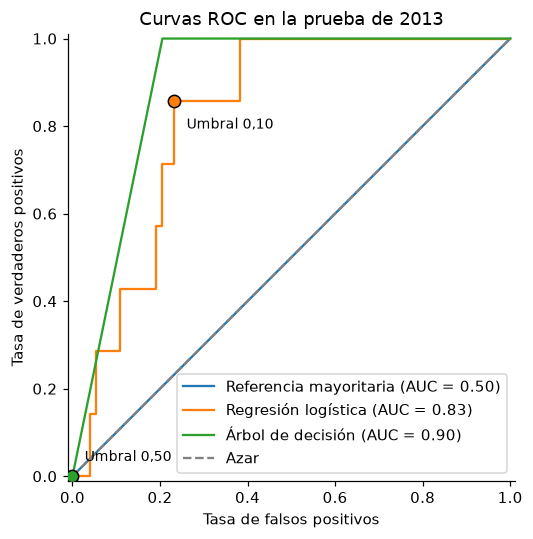

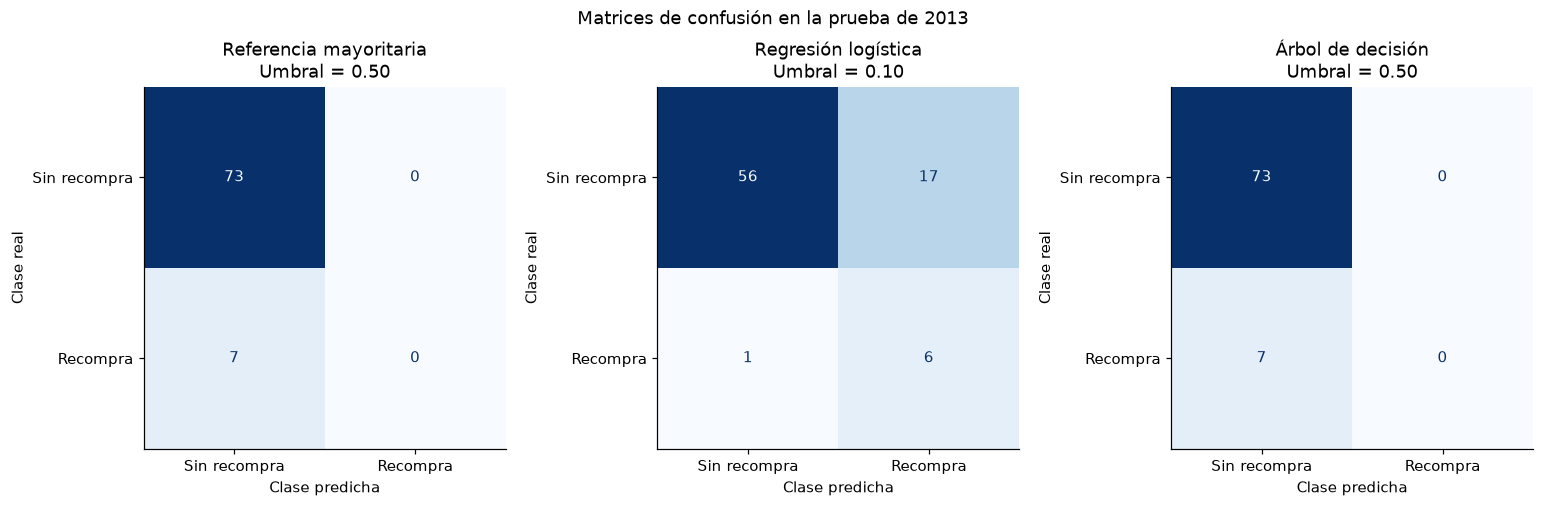

In [317]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig_roc, eje_roc = plt.subplots(figsize=(8, 5))
fig_matrices, ejes_matrices = plt.subplots(
    1, 3, figsize=(14, 4.5), layout="constrained"
)

for (familia, nombre), eje_matriz in zip(
    nombres_evaluacion.items(), ejes_matrices
):
    modelo = modelos_ajustados[familia]
    umbral = umbrales_modelos[familia]
    indice_recompra = list(modelo.classes_).index(1)

    probabilidades = modelo.predict_proba(X_prueba)[:, indice_recompra]
    predicciones = (probabilidades >= umbral).astype(int)

    RocCurveDisplay.from_predictions(
        y_prueba,
        probabilidades,
        name=nombre,
        ax=eje_roc,
    )
    
    if familia in ("RegresionLogistica", "ArbolDecision"):
        reales = y_prueba.to_numpy()
        tasa_falsos_positivos = (predicciones[reales == 0] == 1).mean()
        recall = (predicciones[reales == 1] == 1).mean()

        color = eje_roc.lines[-1].get_color()
        eje_roc.scatter(
            tasa_falsos_positivos,
            recall,
            color=color,
            edgecolor="black",
            s=65,
            zorder=5,
        )
        eje_roc.annotate(
            f"Umbral {umbral:.2f}".replace(".", ","),
            (tasa_falsos_positivos, recall),
            xytext=(8, -18) if familia == "RegresionLogistica" else (8, 10),
            textcoords="offset points",
            fontsize=9,
        )

    ConfusionMatrixDisplay.from_predictions(
        y_prueba,
        predicciones,
        labels=[0, 1],
        display_labels=["Sin recompra", "Recompra"],
        cmap="Blues",
        colorbar=False,
        values_format="d",
        ax=eje_matriz,
    )
    eje_matriz.set_title(f"{nombre}\nUmbral = {umbral:.2f}")
    eje_matriz.set_xlabel("Clase predicha")
    eje_matriz.set_ylabel("Clase real")

eje_roc.plot([0, 1], [0, 1], "--", color="gray", label="Azar")
eje_roc.set_title("Curvas ROC en la prueba de 2013")
eje_roc.set_xlabel("Tasa de falsos positivos")
eje_roc.set_ylabel("Tasa de verdaderos positivos")
eje_roc.legend(loc="lower right")
fig_roc.tight_layout()

fig_matrices.suptitle("Matrices de confusión en la prueba de 2013")

fig_roc.savefig(
    ruta_figuras / "fase3_curvas_roc.png", dpi=160, bbox_inches="tight"
)
fig_matrices.savefig(
    ruta_figuras / "fase3_matrices_confusion.png", dpi=160, bbox_inches="tight"
)
plt.show()

### Predicciones y análisis de errores en 2013

Se guarda una fila por modelo, cliente y mes de corte. Cada fila incluye el mes en que se observó la recompra, el resultado real, la probabilidad estimada, el umbral aplicado y la clase predicha.

En la regresión logística, una falsa alarma es un caso que el modelo habría priorizado y que no volvió a comprar. Una recompra perdida es un caso que sí volvió a comprar y quedó fuera de la lista priorizada. Con el umbral de 0,10, la logística emitió 23 alertas: 6 correspondieron a recompras reales y 17 fueron falsas alarmas. Además, dejó pasar 1 de las 7 recompras observadas.

El resumen mensual permite ver si los errores se concentraron en determinados meses. El detalle de la recompra perdida permite rastrear el caso hasta su fila cliente-mes.

In [318]:
assert X_prueba.index.equals(y_prueba.index)

claves_prueba = prueba_reservada.loc[
    X_prueba.index, ["IdCliente", "MesCorte", "MesResultado"]
]

predicciones_por_modelo = []

for familia, nombre in nombres_evaluacion.items():
    modelo = modelos_ajustados[familia]
    umbral = umbrales_modelos[familia]
    indice_recompra = list(modelo.classes_).index(1)

    detalle = claves_prueba.copy()
    detalle["Modelo"] = nombre
    detalle["Real"] = y_prueba.to_numpy()
    detalle["ProbabilidadRecompra"] = modelo.predict_proba(X_prueba)[:, indice_recompra]
    detalle["Umbral"] = umbral
    detalle["Prediccion"] = (detalle["ProbabilidadRecompra"] >= umbral).astype(int)

    detalle["FalsaAlarma"] = detalle["Real"].eq(0) & detalle["Prediccion"].eq(1)
    detalle["RecompraPerdida"] = detalle["Real"].eq(1) & detalle["Prediccion"].eq(0)
    detalle["RecompraDetectada"] = detalle["Real"].eq(1) & detalle["Prediccion"].eq(1)
    predicciones_por_modelo.append(detalle)

predicciones_prueba = pd.concat(predicciones_por_modelo, ignore_index=True)

assert len(predicciones_prueba) == len(X_prueba) * len(nombres_evaluacion)
assert not predicciones_prueba.duplicated(["Modelo", "IdCliente", "MesCorte"]).any()

ruta_predicciones = ruta_tablas / "fase3_predicciones_prueba.csv"
predicciones_prueba.to_csv(ruta_predicciones, index=False, encoding="utf-8-sig")

logistica_prueba = predicciones_prueba.loc[
    predicciones_prueba["Modelo"].eq(nombres_evaluacion["RegresionLogistica"])
]

resumen_mensual_logistica = logistica_prueba.groupby("MesResultado").agg(
    Casos=("Real", "size"),
    RecomprasReales=("Real", "sum"),
    Alertas=("Prediccion", "sum"),
    RecomprasDetectadas=("RecompraDetectada", "sum"),
    FalsasAlarmas=("FalsaAlarma", "sum"),
    RecomprasPerdidas=("RecompraPerdida", "sum"),
)

print(f"Predicciones exportadas: {len(predicciones_prueba)} filas")
print(f"Archivo guardado en: {ruta_predicciones}")

print("\nResumen mensual de la regresión logística")
display(resumen_mensual_logistica)

print("\nDetalle de la recompra perdida por la regresión logística")
display(logistica_prueba.loc[
    logistica_prueba["RecompraPerdida"],
    ["IdCliente", "MesCorte", "MesResultado", "ProbabilidadRecompra", "Umbral"],
])

Predicciones exportadas: 240 filas
Archivo guardado en: d:\Trabajos U\Mineria de datos\Proyecto3-mineria-datos\resultados\tablas\fase3_predicciones_prueba.csv

Resumen mensual de la regresión logística


,Casos,RecomprasReales,Alertas,RecomprasDetectadas,FalsasAlarmas,RecomprasPerdidas
MesResultado,,,,,,
2013-01,7,0,1,0,1,0
2013-02,7,0,1,0,1,0
2013-03,5,0,1,0,1,0
2013-04,7,0,1,0,1,0
2013-05,5,0,1,0,1,0
2013-06,7,1,4,1,3,0
2013-07,7,1,3,1,2,0
2013-08,7,1,3,1,2,0
2013-09,7,1,3,1,2,0



Detalle de la recompra perdida por la regresión logística


,IdCliente,MesCorte,MesResultado,ProbabilidadRecompra,Umbral
147,6,2013-10,2013-11,0.071586,0.1


### Interpretación de los errores de la regresión logística

La regresión logística detectó 6 de las 7 recompras observadas en 2013 y generó 17 falsas alarmas. Entre enero y mayo emitió una alerta por mes, y las cinco fueron falsas porque en esos meses no hubo recompras. Junio concentró el mayor número de falsas alarmas en un solo mes, con tres.

La única recompra perdida fue la del cliente 6. Al cierre de octubre, el modelo estimó una probabilidad de recompra de 7,16 %, por debajo del umbral de 10 %. El cliente volvió a comprar en noviembre.

Si se usaran las alertas para priorizar contactos, el equipo habría priorizado 23 casos. De ellos, 6 correspondieron a recompras observadas y 17 a clientes que no volvieron a comprar ese mes.

### Desempeño mensual de la regresión logística

La gráfica muestra cuántas recompras detectó la logística, cuántas dejó pasar y cuántas falsas alarmas generó en cada mes de resultado de 2013, con el umbral fijo de 0,10.

Entre enero y mayo hubo una alerta por mes y las cinco fueron falsas. Junio registró la mayor cantidad de falsas alarmas en un solo mes, con tres. En noviembre ocurrió la única recompra perdida.

Para Grupo Innova S.A., el desglose mensual permite revisar cuántos casos tendría que atender el equipo comercial y cuántos de ellos terminaron en una recompra observada.

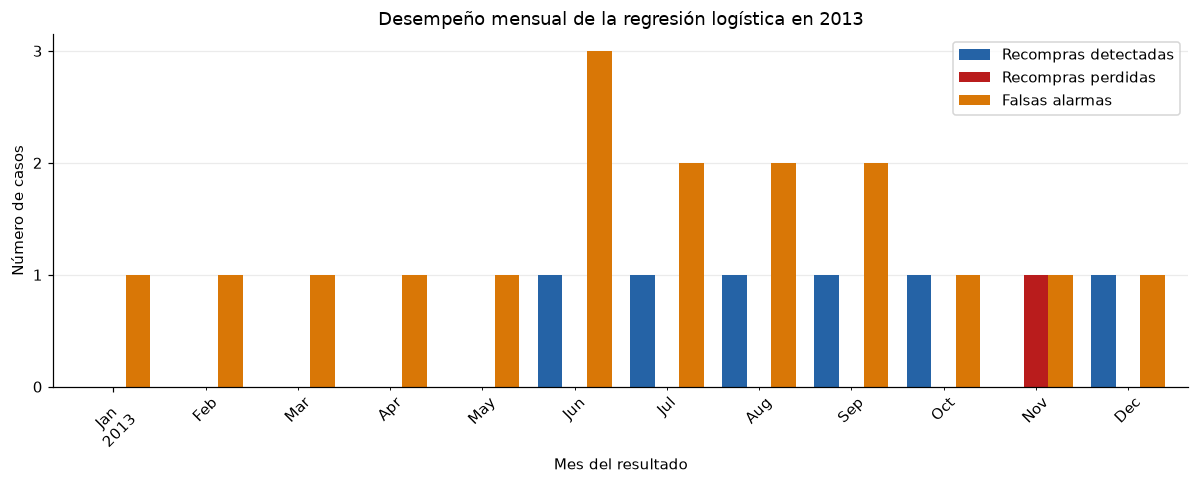

In [319]:
import matplotlib.pyplot as plt

errores_mensuales = resumen_mensual_logistica[
    ["RecomprasDetectadas", "RecomprasPerdidas", "FalsasAlarmas"]
].rename(columns={
    "RecomprasDetectadas": "Recompras detectadas",
    "RecomprasPerdidas": "Recompras perdidas",
    "FalsasAlarmas": "Falsas alarmas",
})

eje = errores_mensuales.plot.bar(
    figsize=(11, 4.5),
    color=["#2563A6", "#B91C1C", "#D97706"],
    width=0.8,
    rot=45,
)

eje.set_title("Desempeño mensual de la regresión logística en 2013")
eje.set_xlabel("Mes del resultado")
eje.set_ylabel("Número de casos")
eje.set_yticks(range(int(errores_mensuales.max().max()) + 1))
eje.grid(axis="y", alpha=0.25)
eje.set_axisbelow(True)

figura = eje.get_figure()
figura.tight_layout()
figura.savefig(
    ruta_figuras / "fase3_desempeno_mensual_logistica.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

### Selección del modelo para detectar recompras

Con el F1 de la clase recompra como criterio de selección, se elige la **regresión logística** entre los modelos evaluados. En la prueba de 2013, con el umbral de 0,10 fijado en la Fase II, obtuvo un **F1 de 0,40**. Detectó **6 de las 7 recompras** y generó **17 falsas alarmas**. Esto equivale a un recall de 85,71 % y una precisión de 26,09 %.

El árbol de decisión obtuvo el mayor ROC/AUC (0,8973), lo que indica que sus puntuaciones ordenaron mejor los casos de recompra en esta prueba. Con el umbral de 0,50 fijado en la Fase II, emitió cero alertas y su F1 fue 0,00. La referencia mayoritaria también emitió cero alertas.

Para Grupo Innova S.A., usar la regresión logística como filtro habría significado revisar 23 alertas en los casos evaluados de 2013. De esas alertas, 6 correspondieron a recompras observadas y 17 a casos que no recompraron. Además, una recompra quedó fuera de la lista priorizada.

Con los umbrales fijados, la logística obtuvo el mayor F1 de recompra (0,40). Ese valor se observó en el mismo bloque de 2013 utilizado para comparar y seleccionar el modelo. Con solo siete recompras en la prueba, detectar un caso más o menos cambia el recall en unos 14,3 puntos porcentuales.

In [320]:
f1_maximo = comparacion_prueba["F1"].max()
modelos_con_mejor_f1 = comparacion_prueba.loc[
    comparacion_prueba["F1"].eq(f1_maximo)
]

print(f"Criterio de selección: F1 de recompra (máximo observado: {f1_maximo:.2f})")

display(modelos_con_mejor_f1[[
    "Modelo", "Umbral", "F1", "Precisión", "Recall", "ROC/AUC",
    "Recompras detectadas", "Recompras perdidas", "Falsas alarmas",
]].round(4))

Criterio de selección: F1 de recompra (máximo observado: 0.40)


,Modelo,Umbral,F1,Precisión,Recall,ROC/AUC,Recompras detectadas,Recompras perdidas,Falsas alarmas
1,Regresión logística,0.1,0.4,0.2609,0.8571,0.8258,6,1,17


### Comparación con un cupo de 23 casos

Se simula un cupo de 23 revisiones para el conjunto de prueba de 2013, igual al número de alertas que produjo la regresión logística con su umbral fijado. Para cada modelo se ordenan los casos de mayor a menor probabilidad de recompra y se seleccionan los primeros 23.

Los empates se resuelven por mes de resultado más temprano y luego por identificador de cliente ascendente. Si un empate cruza el puesto 23, la tabla también muestra cuántas recompras se podrían detectar como mínimo y como máximo según cuáles casos empatados entren en el cupo.

Esta comparación es exploratoria porque el cupo se definió a partir de los resultados observados en 2013. La selección principal del modelo se mantiene basada en el F1 con los umbrales fijados en la Fase II.


In [321]:
cupo = 23
filas_cupo = []

for nombre, casos in predicciones_prueba.groupby("Modelo", sort=False):
    ordenados = casos.sort_values(
        ["ProbabilidadRecompra", "MesResultado", "IdCliente"],
        ascending=[False, True, True],
    )
    seleccionados = ordenados.head(cupo)
    detectadas = int(seleccionados["Real"].sum())
    recompras_reales = int(casos["Real"].sum())

    # Separa los casos que entran por puntuación de los empatados en el corte.
    puntuacion_corte = seleccionados["ProbabilidadRecompra"].iloc[-1]
    por_encima = ordenados.loc[
        ordenados["ProbabilidadRecompra"].gt(puntuacion_corte)
    ]
    empatados = ordenados.loc[
        ordenados["ProbabilidadRecompra"].eq(puntuacion_corte)
    ]

    plazas_empate = cupo - len(por_encima)
    positivos_fijos = int(por_encima["Real"].sum())
    positivos_empatados = int(empatados["Real"].sum())
    negativos_empatados = len(empatados) - positivos_empatados

    filas_cupo.append({
        "Modelo": nombre,
        "Casos revisados": len(seleccionados),
        "Recompras detectadas": detectadas,
        "Precisión": detectadas / cupo,
        "Recall": detectadas / recompras_reales,
        "Empate en el corte": len(empatados) > plazas_empate,
        "Mínimo según desempate": positivos_fijos + max(
            0, plazas_empate - negativos_empatados
        ),
        "Máximo según desempate": positivos_fijos + min(
            plazas_empate, positivos_empatados
        ),
    })

comparacion_cupo = pd.DataFrame(filas_cupo)
display(comparacion_cupo.round(4))

,Modelo,Casos revisados,Recompras detectadas,Precisión,Recall,Empate en el corte,Mínimo según desempate,Máximo según desempate
0,Referencia mayoritaria,23,0,0.0000,0.0000,True,0,7
1,Regresión logística,23,6,0.2609,0.8571,False,6,6
2,Árbol de decisión,23,7,0.3043,1.0000,True,7,7


### Interpretación de la comparación con cupo fijo

Con un cupo de 23 revisiones en la prueba de 2013, el árbol de decisión priorizó las 7 recompras observadas y la regresión logística priorizó 6. El empate en el corte del árbol no cambió ese conteo. La referencia mayoritaria asignó la misma puntuación a todos los casos, por lo que su resultado dependió del desempate.

El resultado depende de cómo se decida a quién revisar. Con los umbrales fijados en la Fase II, la logística obtuvo el mayor F1 y el árbol no emitió alertas. Al ordenar los casos y fijar un cupo común, el árbol recuperó una recompra más. Como el cupo de 23 se definió a partir de los resultados de 2013, esta comparación es exploratoria y conviene comprobarla en otro período antes de adoptar esa regla.

### Cálculo de la importancia por permutación

Se evalúa la regresión logística en los bloques de validación de 2010 y 2011. Para cada bloque se usa el modelo entrenado con los años anteriores y el umbral de 0,10 fijado en la Fase II.

Se calcula el F1 de recompra con los datos originales y luego se desordena una variable a la vez. Se repite la permutación 30 veces por variable y se registra la caída promedio del F1. El bloque de 2012 queda fuera de este análisis porque no tuvo recompras observadas. Los datos de 2013 se mantienen como prueba final.

In [322]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score

familia_importancia = "RegresionLogistica"
umbral_importancia = umbrales_modelos[familia_importancia]


def f1_recompra_con_umbral(modelo, datos, etiquetas):
    indice_recompra = list(modelo.classes_).index(1)
    probabilidades = modelo.predict_proba(datos)[:, indice_recompra]
    predicciones = (probabilidades >= umbral_importancia).astype(int)
    return f1_score(etiquetas, predicciones, pos_label=1, zero_division=0)


caidas_por_anio = {}

for anio, _, indices_validacion in bloques_temporales:
    if anio not in (2010, 2011):
        continue

    modelo_bloque = modelos_validacion[familia_importancia][anio]
    X_bloque = X_desarrollo.loc[indices_validacion]
    y_bloque = y_desarrollo.loc[indices_validacion]

    f1_original = f1_recompra_con_umbral(modelo_bloque, X_bloque, y_bloque)
    print(f"F1 original en validación {anio}: {f1_original:.4f}")

    resultado = permutation_importance(
        modelo_bloque,
        X_bloque,
        y_bloque,
        scoring=f1_recompra_con_umbral,
        n_repeats=30,
        random_state=SEMILLA,
    )

    caidas_por_anio[f"CaidaF1_{anio}"] = pd.Series(
        resultado.importances_mean,
        index=X_bloque.columns,
    )

F1 original en validación 2010: 0.5185
F1 original en validación 2011: 0.4000


### Caída de F1 por variable

La tabla muestra cuánto cambió el F1 de recompra al permutar cada variable en 2010 y 2011. La última columna promedia ambos años con el mismo peso.

Una caída positiva indica que el F1 empeoró al desordenar la variable. Un valor cercano a cero indica poco cambio. Un valor negativo indica que el F1 mejoró en promedio al permutarla.

In [323]:
importancia_logistica = pd.DataFrame(caidas_por_anio)
importancia_logistica["CaidaF1Promedio"] = importancia_logistica[
    ["CaidaF1_2010", "CaidaF1_2011"]
].mean(axis=1)

importancia_logistica = (
    importancia_logistica
    .sort_values("CaidaF1Promedio", ascending=False)
    .rename_axis("Variable")
    .reset_index()
)

ruta_importancia = ruta_tablas / "fase3_importancia_logistica.csv"
importancia_logistica.to_csv(ruta_importancia, index=False, encoding="utf-8-sig")

display(importancia_logistica.round(4))

,Variable,CaidaF1_2010,CaidaF1_2011,CaidaF1Promedio
0,Gasto90dUM,0.1551,0.1691,0.1621
1,RecenciaDias,0.1760,0.0697,0.1228
2,AntiguedadObservadaDias,0.2069,0.0106,0.1088
3,PaisCliente,0.0056,0.0209,0.0132
4,Generos90d,0.0000,0.0000,0.0000
5,DiasVentanaObservados,0.0000,0.0000,0.0000
6,Facturas90d,-0.0040,0.0006,-0.0017


### Interpretación de las variables más influyentes

El gasto de los últimos 90 días (`Gasto90dUM`) fue la variable con mayor caída promedio de F1 (0,1621). Al desordenarla, el F1 cayó 0,1551 en 2010 y 0,1691 en 2011. Esto indica que el monto gastado recientemente aportó información para detectar recompras en ambos bloques.

La recencia (`RecenciaDias`), que mide los días desde la última compra, tuvo la segunda mayor caída promedio (0,1228). Su aporte fue mayor en 2010 que en 2011. La antigüedad observada (`AntiguedadObservadaDias`), que mide los días desde la primera compra registrada, tuvo una caída promedio de 0,1088, impulsada principalmente por el resultado de 2010.

Estos resultados describen cuánto dependieron las predicciones de cada variable en los bloques evaluados. La permutación no indica si un gasto mayor aumenta o disminuye la probabilidad estimada, ni permite concluir que aumentar el gasto cause una recompra.


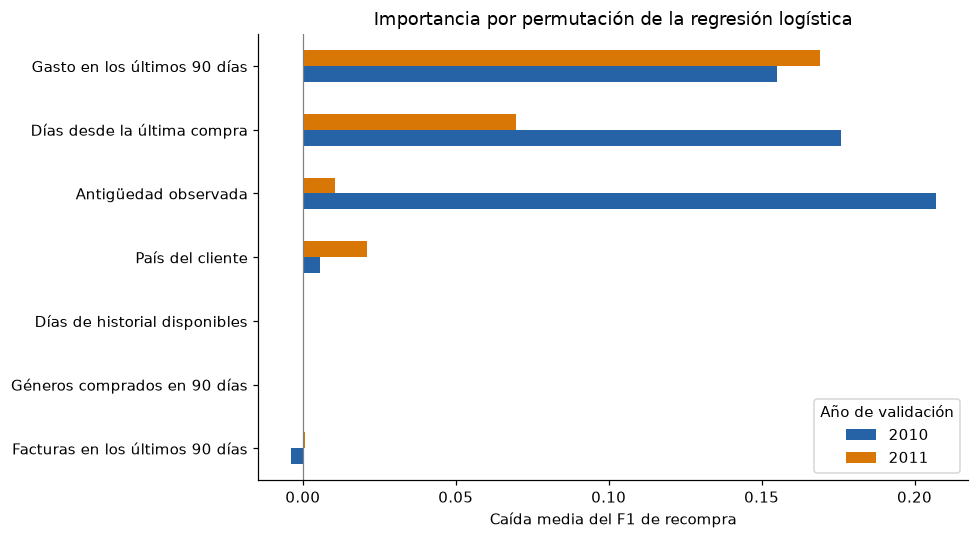

In [324]:
import matplotlib.pyplot as plt

nombres_variables = {
    "Gasto90dUM": "Gasto en los últimos 90 días",
    "RecenciaDias": "Días desde la última compra",
    "AntiguedadObservadaDias": "Antigüedad observada",
    "PaisCliente": "País del cliente",
    "Generos90d": "Géneros comprados en 90 días",
    "DiasVentanaObservados": "Días de historial disponibles",
    "Facturas90d": "Facturas en los últimos 90 días",
}

datos_grafico = (
    importancia_logistica
    .sort_values("CaidaF1Promedio")
    .set_index("Variable")[["CaidaF1_2010", "CaidaF1_2011"]]
    .rename(index=nombres_variables, columns={
        "CaidaF1_2010": "2010",
        "CaidaF1_2011": "2011",
    })
)

eje = datos_grafico.plot.barh(figsize=(9, 5), color=["#2563A6", "#D97706"])
eje.axvline(0, color="gray", linewidth=0.8)
eje.set_title("Importancia por permutación de la regresión logística")
eje.set_xlabel("Caída media del F1 de recompra")
eje.set_ylabel("")
eje.legend(title="Año de validación")

figura_importancia = eje.get_figure()
figura_importancia.tight_layout()
figura_importancia.savefig(
    ruta_figuras / "fase3_importancia_logistica.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()